In [ ]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import tifffile as tif
import matplotlib.pyplot as plt

from scipy import ndimage as ndi
from skimage.color import label2rgb
from skimage.segmentation import expand_labels

from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    balanced_accuracy_score,
)


In [ ]:
DATA_ROOT = Path(os.environ.get("PV_DATA_ROOT", "./datasets")).expanduser().resolve()

SR_META = DATA_ROOT / "single-row" / "metadata.csv"
DR_META = DATA_ROOT / "double-row" / "metadata.csv"

SR_THERM_DIR = DATA_ROOT / "single-row" / "thermal images"
DR_THERM_DIR = DATA_ROOT / "double-row" / "thermal images"
DR_RGB_DIR = DATA_ROOT / "double-row" / "rgb images"

# Where we will save extracted module crops
OUT_ROOT = Path("./pv_module_crops")
OUT_ROOT.mkdir(parents=True, exist_ok=True)

# Crops used in the Kaggle notebook (dataset-specific; you can tune later)
IR_CROP = dict(left=0, top=75, right=640, bottom=490)
RGB_CROP = dict(left=120, top=0, right=1150, bottom=720)

# Training config
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BATCH_SIZE = 64
EPOCHS = 8
LR = 1e-3
IMG_SIZE = 224
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

print("DEVICE:", DEVICE)


DEVICE: cpu


In [ ]:
def load_metadata(path: Path, is_double_row: bool):
    df = pd.read_csv(path).copy()

    # Normalize column names from Kaggle dataset
    rename_map = {"thermal image name": "thermal_image_name"}
    if is_double_row:
        rename_map["rgb image name"] = "rgb_image_name"

    df = df.rename(columns=rename_map)

    # Parse timestamp if present
    if "timestamp" in df.columns:
        df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

    return df


sr_metadata = load_metadata(SR_META, is_double_row=False)
dr_metadata = load_metadata(DR_META, is_double_row=True)

sr_metadata.head(), dr_metadata.head()


(                timestamp  longitude   latitude thermal_image_name
 0 2021-10-11 10:15:38.390  10.180881  49.613338  frame_000000.tiff
 1 2021-10-11 10:15:38.480  10.180881  49.613338  frame_000001.tiff
 2 2021-10-11 10:15:38.610  10.180881  49.613338  frame_000002.tiff
 3 2021-10-11 10:15:38.750  10.180881  49.613338  frame_000003.tiff
 4 2021-10-11 10:15:38.880  10.180881  49.613338  frame_000004.tiff,
                 timestamp  longitude   latitude thermal_image_name  \
 0 2021-10-11 10:29:44.540  10.180867  49.612644  frame_000000.tiff   
 1 2021-10-11 10:29:44.550  10.180867  49.612644  frame_000001.tiff   
 2 2021-10-11 10:29:44.680  10.180867  49.612644  frame_000002.tiff   
 3 2021-10-11 10:29:44.810  10.180867  49.612644  frame_000003.tiff   
 4 2021-10-11 10:29:44.950  10.180867  49.612644  frame_000004.tiff   
 
      rgb_image_name  
 0  frame_000000.jpg  
 1  frame_000001.jpg  
 2  frame_000002.jpg  
 3  frame_000003.jpg  
 4  frame_000004.jpg  )

In [ ]:
class Thermogram:
    def __init__(self, path: Path):
        self.path = path

    @property
    def celsius(self) -> np.ndarray:
        # Kaggle conversion used: raw*0.04 - 273.15
        return (tif.imread(self.path.as_posix()) * 0.04) - 273.15

    def render8(self) -> np.ndarray:
        img = self.celsius.astype(np.float32)
        img = (img - img.min()) / (img.max() - img.min() + 1e-6)
        return (img * 255.0).astype(np.uint8)


def load_rgb(path: Path) -> np.ndarray:
    img = cv2.imread(path.as_posix(), cv2.IMREAD_COLOR)  # BGR
    if img is None:
        raise FileNotFoundError(f"RGB not found: {path}")
    return img


def load_thermal(path: Path) -> Thermogram:
    if not path.exists():
        raise FileNotFoundError(f"Thermal not found: {path}")
    return Thermogram(path)


In [ ]:
def attach_paths_double_row(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["rgb_path"] = df["rgb_image_name"].apply(lambda x: DR_RGB_DIR / x)
    df["thermal_path"] = df["thermal_image_name"].apply(lambda x: DR_THERM_DIR / x)
    return df


dr_metadata = attach_paths_double_row(dr_metadata)

dr_metadata[["rgb_path", "thermal_path"]].head()


In [ ]:
def preprocess_rgb_image_hsv_otsu_bgr(bgr: np.ndarray) -> np.ndarray:
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    masks = []
    for ci, ch in enumerate(cv2.split(hsv)):
        ch = cv2.GaussianBlur(ch, (3, 3), 0)
        max_val = 179 if ci == 0 else 255
        _, mask = cv2.threshold(ch, 0, max_val, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        masks.append(mask)

    m = cv2.bitwise_and(masks[0], masks[1])
    m = cv2.bitwise_and(m, masks[2])
    return m


def postprocess_binary_mask(mask: np.ndarray) -> np.ndarray:
    # mask is 0/255
    mask = cv2.medianBlur(mask, 5)

    kernel = np.ones((7, 7), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

    mask = ndi.binary_fill_holes(mask > 0)
    return mask.astype(np.uint8)


def connected_components(mask01: np.ndarray):
    # expects 0/1
    n, labels = cv2.connectedComponents(mask01.astype(np.uint8))
    return n, labels


In [ ]:
def crop_image(arr: np.ndarray, box: dict) -> np.ndarray:
    l, t, r, b = box["left"], box["top"], box["right"], box["bottom"]
    return arr[t:b, l:r]


def make_aligned_pair(rgb_bgr: np.ndarray, thermal8: np.ndarray):
    # Crop thermal (already grayscale 8-bit)
    th_crop = crop_image(thermal8, IR_CROP)

    # Crop rgb then resize to thermal crop size
    rgb_crop = crop_image(rgb_bgr, RGB_CROP)
    rgb_crop = cv2.resize(
        rgb_crop, (th_crop.shape[1], th_crop.shape[0]), interpolation=cv2.INTER_LINEAR
    )
    return rgb_crop, th_crop


In [ ]:
def robust_mad(x: np.ndarray) -> float:
    med = np.median(x)
    mad = np.median(np.abs(x - med)) + 1e-6
    return mad


def bbox_from_label(labels: np.ndarray, label_id: int):
    ys, xs = np.where(labels == label_id)
    if len(xs) == 0:
        return None
    x1, x2 = xs.min(), xs.max()
    y1, y2 = ys.min(), ys.max()
    return x1, y1, x2 + 1, y2 + 1  # python slicing


def extract_module_crops(
    rgb_crop_bgr: np.ndarray,
    thermal8_crop: np.ndarray,
    thermal_celsius_crop: np.ndarray,
    min_area: int = 500,
    pad: int = 6,
):
    # 1) segment modules from RGB crop
    mask255 = preprocess_rgb_image_hsv_otsu_bgr(rgb_crop_bgr)
    mask01 = postprocess_binary_mask(mask255)

    n, labels = connected_components(mask01)

    # 2) robust baseline for pseudo-labeling
    img_med = np.median(thermal_celsius_crop)
    img_mad = robust_mad(thermal_celsius_crop)

    samples = []
    H, W = thermal8_crop.shape

    for lab in range(1, n):
        area = int((labels == lab).sum())
        if area < min_area:
            continue

        bb = bbox_from_label(labels, lab)
        if bb is None:
            continue
        x1, y1, x2, y2 = bb

        # pad bbox
        x1 = max(0, x1 - pad)
        y1 = max(0, y1 - pad)
        x2 = min(W, x2 + pad)
        y2 = min(H, y2 + pad)

        rgb_patch = rgb_crop_bgr[y1:y2, x1:x2]
        th8_patch = thermal8_crop[y1:y2, x1:x2]
        thC_patch = thermal_celsius_crop[y1:y2, x1:x2]

        # module thermal score
        t95 = float(np.percentile(thC_patch, 95))
        score = (t95 - img_med) / img_mad

        # pseudo-label: defect if score > k
        k = 6.0
        y = int(score > k)

        samples.append(
            {
                "rgb_patch": rgb_patch,
                "th8_patch": th8_patch,
                "label": y,
                "score": score,
                "bbox": (x1, y1, x2, y2),
                "area": area,
            }
        )

    return samples, mask01, labels


In [ ]:
def save_patch(path: Path, arr: np.ndarray):
    path.parent.mkdir(parents=True, exist_ok=True)
    np.save(path.as_posix(), arr)


def build_module_dataset(df: pd.DataFrame, out_root: Path, max_images: int = 200):
    records = []
    used = 0

    for i, row in tqdm(df.iterrows(), total=min(len(df), max_images)):
        if used >= max_images:
            break

        rgb_path = Path(row["rgb_path"])
        th_path = Path(row["thermal_path"])

        try:
            rgb = load_rgb(rgb_path)
            th = load_thermal(th_path)
        except Exception as e:
            continue

        th8 = th.render8()
        # make aligned crop pair
        rgb_crop, th8_crop = make_aligned_pair(rgb, th8)

        # also crop Celsius (same crop box as thermal8)
        thC_crop = crop_image(th.celsius, IR_CROP)

        samples, mask01, labels = extract_module_crops(rgb_crop, th8_crop, thC_crop)

        # Save each module crop
        for m, s in enumerate(samples):
            rgb_save = out_root / "rgb" / f"img{i:05d}_m{m:03d}.npy"
            th_save = out_root / "thermal" / f"img{i:05d}_m{m:03d}.npy"

            save_patch(rgb_save, s["rgb_patch"])
            save_patch(
                th_save, s["th8_patch"]
            )  # store 8-bit; you can also store Celsius

            records.append(
                {
                    "image_index": i,
                    "module_index": m,
                    "rgb_npy": rgb_save.as_posix(),
                    "thermal_npy": th_save.as_posix(),
                    "label": s["label"],
                    "score": float(s["score"]),
                    "area": int(s["area"]),
                }
            )

        used += 1

    index_df = pd.DataFrame(records)
    index_path = out_root / "index.csv"
    index_df.to_csv(index_path, index=False)
    return index_df


# Start with a small build to verify everything works
index_df = build_module_dataset(dr_metadata, OUT_ROOT, max_images=50)
index_df.head(), len(index_df)


100%|██████████| 50/50 [00:04<00:00, 11.29it/s]


(   image_index  module_index                                rgb_npy  \
 0            0             0  pv_module_crops/rgb/img00000_m000.npy   
 1            0             1  pv_module_crops/rgb/img00000_m001.npy   
 2            0             2  pv_module_crops/rgb/img00000_m002.npy   
 3            0             3  pv_module_crops/rgb/img00000_m003.npy   
 4            0             4  pv_module_crops/rgb/img00000_m004.npy   
 
                                  thermal_npy  label     score  area  
 0  pv_module_crops/thermal/img00000_m000.npy      0  2.275861  2497  
 1  pv_module_crops/thermal/img00000_m001.npy      0  2.103447  1652  
 2  pv_module_crops/thermal/img00000_m002.npy      0  1.913792  1730  
 3  pv_module_crops/thermal/img00000_m003.npy      0  1.896551  2138  
 4  pv_module_crops/thermal/img00000_m004.npy      0  2.103447  2685  ,
 1355)

In [ ]:
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset
from torchvision import transforms
import torch
import numpy as np
import pandas as pd
from pathlib import Path


class PairedModuleDataset(Dataset):
    def __init__(
        self, index_csv: Path, img_size=224, split="train", test_size=0.27, seed=42
    ):
        df = pd.read_csv(index_csv).copy()

        # Stratified split by label to guarantee both classes appear in train/test
        train_df, test_df = train_test_split(
            df, test_size=test_size, random_state=seed, stratify=df["label"]
        )
        self.df = (
            train_df.reset_index(drop=True)
            if split == "train"
            else test_df.reset_index(drop=True)
        )

        # Augmentations
        aug = [transforms.RandomHorizontalFlip(p=0.5)] if split == "train" else []

        self.rgb_tf = transforms.Compose(
            [
                transforms.ToPILImage(),
                transforms.Resize((img_size, img_size)),
                *aug,
                transforms.ToTensor(),
                transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
            ]
        )

        self.th_tf = transforms.Compose(
            [
                transforms.ToPILImage(),
                transforms.Resize((img_size, img_size)),
                *aug,
                transforms.ToTensor(),  # (1,H,W)
                transforms.Normalize((0.5,), (0.25,)),
            ]
        )

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        r = self.df.iloc[idx]
        rgb = np.load(r["rgb_npy"])  # BGR
        th = np.load(r["thermal_npy"])  # HxW uint8

        rgb = rgb[:, :, ::-1].copy()  # BGR -> RGB
        if th.ndim == 2:
            th = th[:, :, None]  # HxW -> HxWx1

        rgb_t = self.rgb_tf(rgb)
        th_t = self.th_tf(th)
        y = torch.tensor(int(r["label"]), dtype=torch.long)
        return rgb_t, th_t, y


In [ ]:
import pandas as pd
import numpy as np
from torch.utils.data import DataLoader

# ---------- 1) Ensure labels are not single-class (percentile relabel) ----------
idx_path = OUT_ROOT / "index.csv"
df_idx = pd.read_csv(idx_path)

print("Before relabel:")
print(df_idx["label"].value_counts(dropna=False))

TOP_FRAC = 0.10  # top 10% hottest modules are "defect" for now
thr = df_idx["score"].quantile(1 - TOP_FRAC)
df_idx["label"] = (df_idx["score"] >= thr).astype(int)

print("\nAfter relabel:")
print(df_idx["label"].value_counts(dropna=False))
print("Threshold used:", thr)

df_idx.to_csv(idx_path, index=False)

# ---------- 2) Create datasets ----------
train_ds = PairedModuleDataset(idx_path, img_size=IMG_SIZE, split="train")
test_ds = PairedModuleDataset(idx_path, img_size=IMG_SIZE, split="test")

print("\nTrain/Test sizes:", len(train_ds), len(test_ds))
print("Train label counts:\n", train_ds.df["label"].value_counts())
print("Test label counts:\n", test_ds.df["label"].value_counts())

# ---------- 3) Create loaders (MPS-safe) ----------
train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=False,
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False,
)


Before relabel:
label
0    1355
Name: count, dtype: int64

After relabel:
label
0    1218
1     137
Name: count, dtype: int64
Threshold used: 2.2931024598696332

Train/Test sizes: 989 366
Train label counts:
 label
0    889
1    100
Name: count, dtype: int64
Test label counts:
 label
0    329
1     37
Name: count, dtype: int64


In [ ]:
import torch

counts = train_ds.df["label"].value_counts().to_dict()
n0 = counts.get(0, 1)
n1 = counts.get(1, 1)

class_weights = torch.tensor([1.0, n0 / max(n1, 1)], dtype=torch.float32).to(DEVICE)
print("Class weights:", class_weights)


Class weights: tensor([1.0000, 8.8900])


ResNet builder (pretrained for RGB)

In [ ]:
import torchvision
import torch.nn as nn


def make_resnet18(in_channels=3, pretrained=False):
    weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    m = torchvision.models.resnet18(weights=weights)

    if in_channels != 3:
        old = m.conv1
        m.conv1 = nn.Conv2d(
            in_channels,
            old.out_channels,
            kernel_size=old.kernel_size,
            stride=old.stride,
            padding=old.padding,
            bias=False,
        )
    return m


Models (RGB / Thermal / Early fusion / Late fusion)

In [ ]:
import torch
import torch.nn as nn


class RGBOnly(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.backbone = make_resnet18(3, pretrained=True)
        self.backbone.fc = nn.Linear(self.backbone.fc.in_features, num_classes)

    def forward(self, rgb, th=None):
        return self.backbone(rgb)


class ThermalOnly(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.backbone = make_resnet18(1, pretrained=False)
        self.backbone.fc = nn.Linear(self.backbone.fc.in_features, num_classes)

    def forward(self, rgb=None, th=None):
        return self.backbone(th)


class EarlyFusion(nn.Module):
    # Stack RGB (3ch) + Thermal (1ch) -> 4 channels
    def __init__(self, num_classes=2):
        super().__init__()
        self.backbone = make_resnet18(4, pretrained=False)
        self.backbone.fc = nn.Linear(self.backbone.fc.in_features, num_classes)

    def forward(self, rgb, th):
        x = torch.cat([rgb, th], dim=1)  # (B,4,H,W)
        return self.backbone(x)


class LateFusion(nn.Module):
    def __init__(self, emb_dim=256, num_classes=2):
        super().__init__()
        self.rgb_net = make_resnet18(3, pretrained=True)
        self.th_net = make_resnet18(1, pretrained=False)

        rgb_in = self.rgb_net.fc.in_features
        th_in = self.th_net.fc.in_features

        self.rgb_net.fc = nn.Identity()
        self.th_net.fc = nn.Identity()

        self.proj_rgb = nn.Linear(rgb_in, emb_dim)
        self.proj_th = nn.Linear(th_in, emb_dim)

        self.head = nn.Sequential(
            nn.ReLU(),
            nn.Linear(emb_dim * 2, emb_dim),
            nn.ReLU(),
            nn.Linear(emb_dim, num_classes),
        )

    def forward(self, rgb, th):
        z1 = self.proj_rgb(self.rgb_net(rgb))
        z2 = self.proj_th(self.th_net(th))
        z = torch.cat([z1, z2], dim=1)
        return self.head(z)


Train/eval utilities (weighted CE + AUC/AP/F1)

In [ ]:
import numpy as np
import torch.nn.functional as F
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    balanced_accuracy_score,
)


def run_epoch(model, loader, optimizer=None, class_weights=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    losses, ys, ps = [], [], []

    for rgb, th, y in loader:
        rgb = rgb.to(DEVICE)
        th = th.to(DEVICE)
        y = y.to(DEVICE)

        with torch.set_grad_enabled(is_train):
            if isinstance(model, RGBOnly):
                logits = model(rgb, None)
            elif isinstance(model, ThermalOnly):
                logits = model(None, th)
            else:
                logits = model(rgb, th)

            loss = F.cross_entropy(logits, y, weight=class_weights)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

        losses.append(loss.item())
        prob = torch.softmax(logits, dim=1)[:, 1].detach().cpu().numpy()
        ps.append(prob)
        ys.append(y.detach().cpu().numpy())

    ys = np.concatenate(ys)
    ps = np.concatenate(ps)

    auc = roc_auc_score(ys, ps) if len(np.unique(ys)) > 1 else np.nan
    ap = average_precision_score(ys, ps) if len(np.unique(ys)) > 1 else np.nan

    pred = (ps > 0.5).astype(int)
    f1 = f1_score(ys, pred) if len(np.unique(ys)) > 1 else np.nan
    bal = balanced_accuracy_score(ys, pred) if len(np.unique(ys)) > 1 else np.nan

    return {
        "loss": float(np.mean(losses)),
        "auc": float(auc),
        "ap": float(ap),
        "f1": float(f1),
        "bal_acc": float(bal),
    }


def train_model(model, epochs=EPOCHS, lr=LR, class_weights=None):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)

    for ep in range(1, epochs + 1):
        tr = run_epoch(model, train_loader, optimizer=opt, class_weights=class_weights)
        te = run_epoch(model, test_loader, optimizer=None, class_weights=class_weights)

        print(
            f"Epoch {ep:02d} | train loss {tr['loss']:.4f} auc {tr['auc']:.3f} ap {tr['ap']:.3f} | "
            f"test loss {te['loss']:.4f} auc {te['auc']:.3f} ap {te['ap']:.3f}"
        )
    return model


In [ ]:
rgb_model = train_model(RGBOnly(), class_weights=class_weights)

Epoch 01 | train loss 0.5555 auc 0.848 ap 0.503 | test loss 7.6871 auc 0.488 ap 0.158
Epoch 02 | train loss 0.3202 auc 0.942 ap 0.806 | test loss 1.0551 auc 0.969 ap 0.837
Epoch 03 | train loss 0.1310 auc 0.991 ap 0.936 | test loss 0.3713 auc 0.986 ap 0.944
Epoch 04 | train loss 0.0984 auc 0.992 ap 0.931 | test loss 0.2869 auc 0.975 ap 0.928
Epoch 05 | train loss 0.0881 auc 0.994 ap 0.951 | test loss 0.3074 auc 0.953 ap 0.825
Epoch 06 | train loss 0.1603 auc 0.984 ap 0.866 | test loss 0.2529 auc 0.985 ap 0.903
Epoch 07 | train loss 0.1252 auc 0.989 ap 0.901 | test loss 0.9258 auc 0.930 ap 0.712
Epoch 08 | train loss 0.1459 auc 0.987 ap 0.916 | test loss 0.2465 auc 0.967 ap 0.873


In [ ]:
def eval_model(model, name):
    m = run_epoch(
        model.to(DEVICE), test_loader, optimizer=None, class_weights=class_weights
    )
    print(
        f"{name:12s} | loss {m['loss']:.4f} | AUC {m['auc']:.3f} | AP {m['ap']:.3f} | "
        f"F1 {m['f1']:.3f} | BalAcc {m['bal_acc']:.3f}"
    )
    return m


print("\n=== Test set results ===")
results = {}
results["RGB"] = eval_model(rgb_model, "RGB-only")


=== Test set results ===
RGB-only     | loss 0.2465 | AUC 0.967 | AP 0.873 | F1 0.810 | BalAcc 0.940


In [ ]:
th_model = train_model(ThermalOnly(), class_weights=class_weights)

Epoch 01 | train loss 0.3965 auc 0.907 ap 0.443 | test loss 0.6691 auc 0.982 ap 0.888
Epoch 02 | train loss 0.1098 auc 0.993 ap 0.964 | test loss 1.0642 auc 0.986 ap 0.871
Epoch 03 | train loss 0.1593 auc 0.984 ap 0.878 | test loss 0.9578 auc 0.985 ap 0.927
Epoch 04 | train loss 0.1703 auc 0.983 ap 0.885 | test loss 0.9441 auc 0.984 ap 0.820
Epoch 05 | train loss 0.0987 auc 0.994 ap 0.947 | test loss 0.0800 auc 0.997 ap 0.967
Epoch 06 | train loss 0.0713 auc 0.997 ap 0.975 | test loss 0.0787 auc 0.996 ap 0.977
Epoch 07 | train loss 0.0793 auc 0.996 ap 0.953 | test loss 0.1061 auc 0.996 ap 0.968
Epoch 08 | train loss 0.1256 auc 0.988 ap 0.876 | test loss 0.2083 auc 0.990 ap 0.939


In [ ]:
def eval_model(model, name):
    m = run_epoch(
        model.to(DEVICE), test_loader, optimizer=None, class_weights=class_weights
    )
    print(
        f"{name:12s} | loss {m['loss']:.4f} | AUC {m['auc']:.3f} | AP {m['ap']:.3f} | "
        f"F1 {m['f1']:.3f} | BalAcc {m['bal_acc']:.3f}"
    )
    return m


print("\n=== Test set results ===")
results = {}
results["TH"] = eval_model(th_model, "Thermal-only")


=== Test set results ===
Thermal-only | loss 0.2083 | AUC 0.990 | AP 0.939 | F1 0.636 | BalAcc 0.915


In [ ]:
early_model = train_model(EarlyFusion(), class_weights=class_weights)

Epoch 01 | train loss 0.4562 auc 0.860 ap 0.510 | test loss 14.5503 auc 0.530 ap 0.099
Epoch 02 | train loss 0.1563 auc 0.986 ap 0.925 | test loss 0.1246 auc 0.989 ap 0.958
Epoch 03 | train loss 0.1526 auc 0.985 ap 0.876 | test loss 0.1212 auc 0.990 ap 0.975
Epoch 04 | train loss 0.1190 auc 0.992 ap 0.933 | test loss 0.5620 auc 0.988 ap 0.968
Epoch 05 | train loss 0.1347 auc 0.990 ap 0.938 | test loss 0.2700 auc 0.992 ap 0.963
Epoch 06 | train loss 0.1043 auc 0.993 ap 0.961 | test loss 0.3498 auc 0.991 ap 0.969
Epoch 07 | train loss 0.0897 auc 0.995 ap 0.969 | test loss 0.4558 auc 0.987 ap 0.975
Epoch 08 | train loss 0.0612 auc 0.998 ap 0.981 | test loss 0.1919 auc 0.984 ap 0.952


In [ ]:
def eval_model(model, name):
    m = run_epoch(
        model.to(DEVICE), test_loader, optimizer=None, class_weights=class_weights
    )
    print(
        f"{name:12s} | loss {m['loss']:.4f} | AUC {m['auc']:.3f} | AP {m['ap']:.3f} | "
        f"F1 {m['f1']:.3f} | BalAcc {m['bal_acc']:.3f}"
    )
    return m


print("\n=== Test set results ===")
results = {}
results["Early"] = eval_model(early_model, "Early-fusion")


=== Test set results ===
Early-fusion | loss 0.1919 | AUC 0.984 | AP 0.952 | F1 0.686 | BalAcc 0.938


In [ ]:
late_model = train_model(LateFusion(), class_weights=class_weights)

Epoch 01 | train loss 0.3675 auc 0.916 ap 0.629 | test loss 0.9557 auc 0.826 ap 0.246
Epoch 02 | train loss 0.1451 auc 0.986 ap 0.875 | test loss 0.5085 auc 0.924 ap 0.612
Epoch 03 | train loss 0.2249 auc 0.971 ap 0.829 | test loss 0.3325 auc 0.967 ap 0.875
Epoch 04 | train loss 0.1332 auc 0.988 ap 0.906 | test loss 0.1449 auc 0.992 ap 0.938
Epoch 05 | train loss 0.1522 auc 0.985 ap 0.856 | test loss 0.5197 auc 0.979 ap 0.841
Epoch 06 | train loss 0.0893 auc 0.993 ap 0.925 | test loss 0.2639 auc 0.987 ap 0.950
Epoch 07 | train loss 0.1403 auc 0.989 ap 0.929 | test loss 0.9162 auc 0.959 ap 0.557
Epoch 08 | train loss 0.1119 auc 0.991 ap 0.930 | test loss 0.0893 auc 0.996 ap 0.971


In [ ]:
def eval_model(model, name):
    m = run_epoch(
        model.to(DEVICE), test_loader, optimizer=None, class_weights=class_weights
    )
    print(
        f"{name:12s} | loss {m['loss']:.4f} | AUC {m['auc']:.3f} | AP {m['ap']:.3f} | "
        f"F1 {m['f1']:.3f} | BalAcc {m['bal_acc']:.3f}"
    )
    return m


print("\n=== Test set results ===")
results = {}
results["Late"] = eval_model(late_model, "Late-fusion")


=== Test set results ===
Late-fusion  | loss 0.0893 | AUC 0.996 | AP 0.971 | F1 0.783 | BalAcc 0.958


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

import torch
import torch.nn.functional as F
from sklearn.metrics import confusion_matrix, roc_curve, precision_recall_curve, auc

idx_path = OUT_ROOT / "index.csv"
df_idx = pd.read_csv(idx_path)


def load_pair_from_row(row):
    """Load RGB (as RGB) and thermal (H,W) from npy paths stored in index.csv."""
    rgb_bgr = np.load(row["rgb_npy"])  # H,W,3 BGR
    rgb = rgb_bgr[:, :, ::-1].copy()  # -> RGB
    th = np.load(row["thermal_npy"])  # H,W uint8
    return rgb, th


def show_rgb(ax, rgb):
    ax.imshow(rgb)
    ax.axis("off")


def show_th(ax, th):
    ax.imshow(th, cmap="gray")
    ax.axis("off")


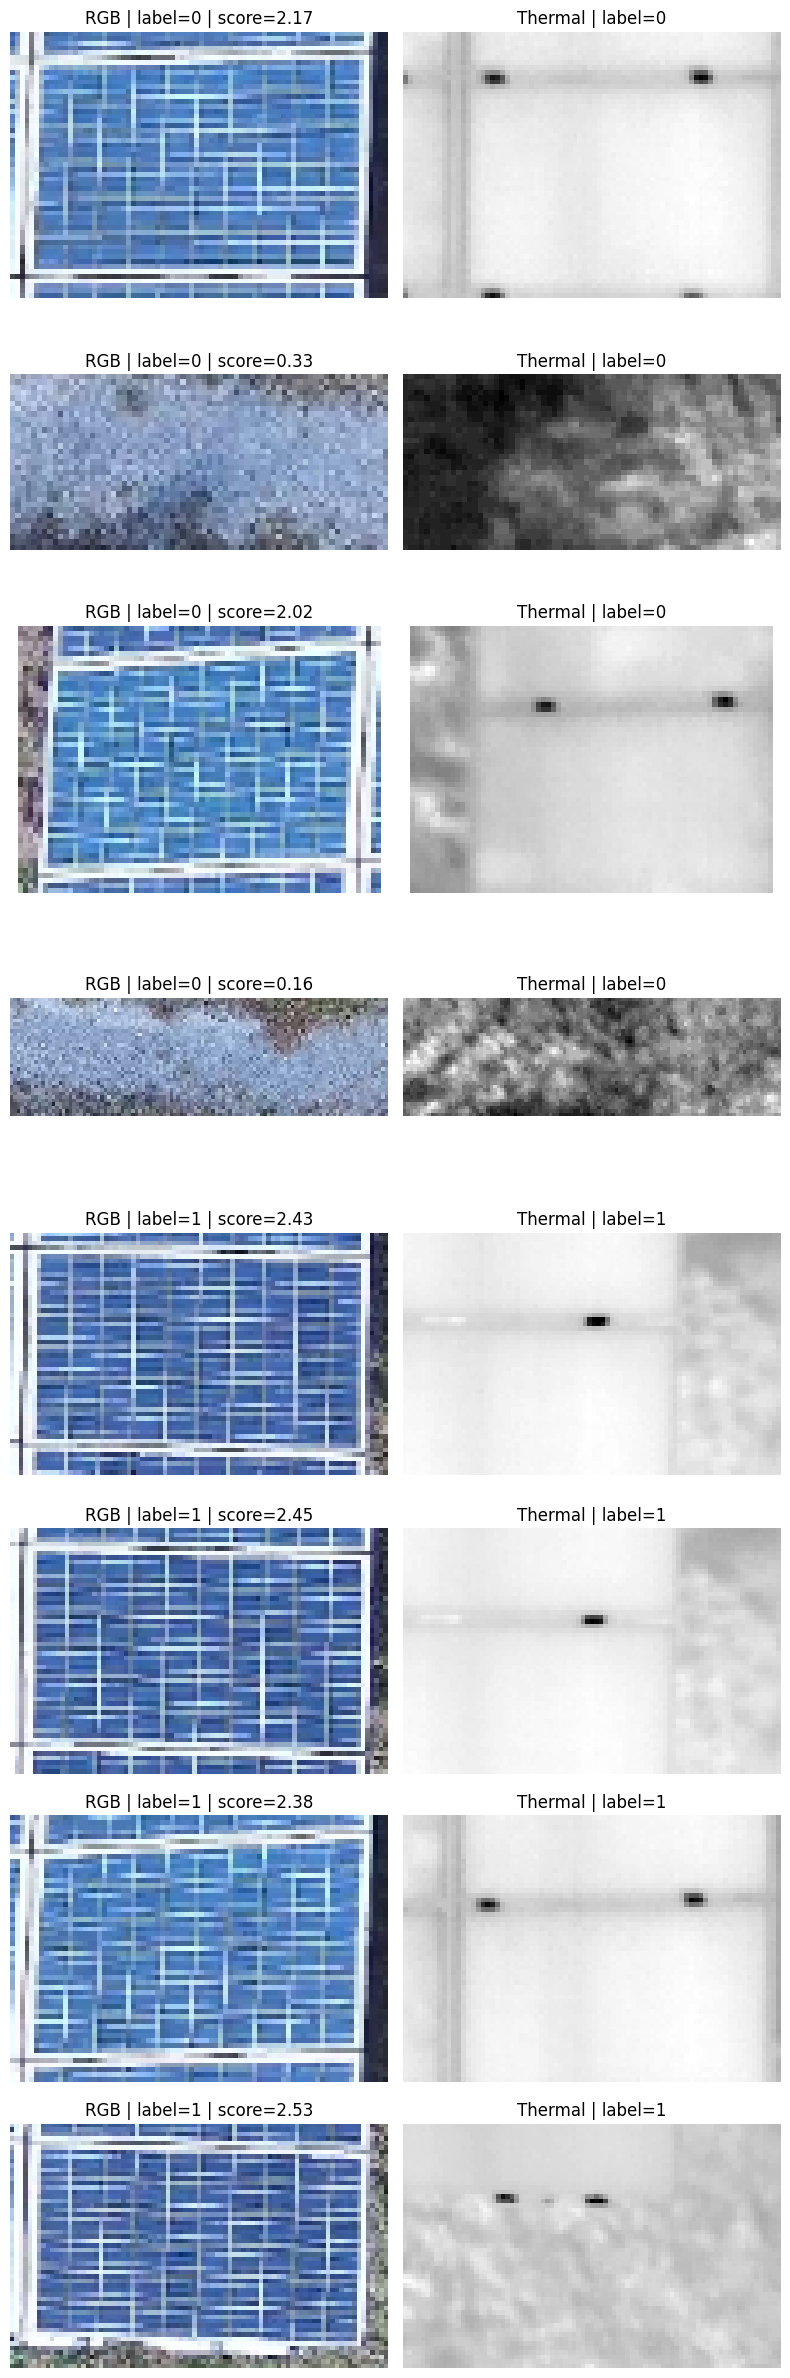

In [ ]:
# Choose how many examples per class
K = 4

pos = df_idx[df_idx["label"] == 1].sample(
    min(K, (df_idx["label"] == 1).sum()), random_state=0
)
neg = df_idx[df_idx["label"] == 0].sample(
    min(K, (df_idx["label"] == 0).sum()), random_state=1
)

rows = pd.concat([neg, pos], axis=0).reset_index(drop=True)

fig, axes = plt.subplots(len(rows), 2, figsize=(8, 3 * len(rows)))
if len(rows) == 1:
    axes = np.array([axes])  # ensure 2D indexing

for i, r in enumerate(rows.itertuples(index=False)):
    row = df_idx.iloc[i] if False else rows.iloc[i]
    rgb, th = load_pair_from_row(row)

    show_rgb(axes[i, 0], rgb)
    axes[i, 0].set_title(f"RGB | label={int(row['label'])} | score={row['score']:.2f}")

    show_th(axes[i, 1], th)
    axes[i, 1].set_title(f"Thermal | label={int(row['label'])}")

plt.tight_layout()
plt.show()


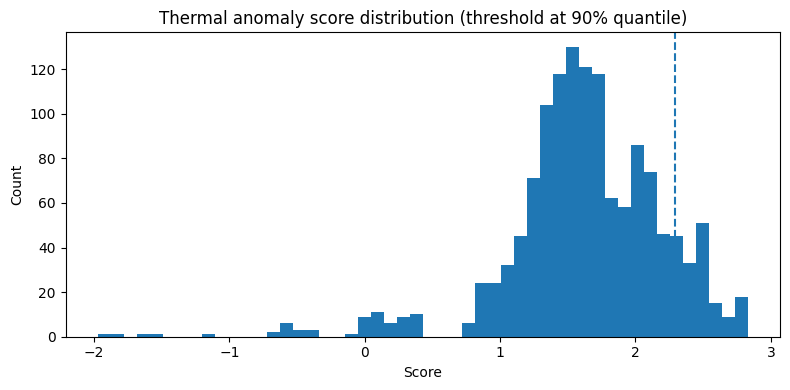

Threshold: 2.2931024598696332
label
0    1218
1     137
Name: count, dtype: int64 
 label
0    0.898893
1    0.101107
Name: proportion, dtype: float64


In [ ]:
TOP_FRAC = 0.10
thr = df_idx["score"].quantile(1 - TOP_FRAC)

plt.figure(figsize=(8, 4))
plt.hist(df_idx["score"].values, bins=50)
plt.axvline(thr, linestyle="--")
plt.title(
    f"Thermal anomaly score distribution (threshold at {1 - TOP_FRAC:.0%} quantile)"
)
plt.xlabel("Score")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

print("Threshold:", thr)
print(
    df_idx["label"].value_counts(), "\n", df_idx["label"].value_counts(normalize=True)
)


In [ ]:
@torch.no_grad()
def predict_on_loader(model, loader):
    model.eval()
    ys, ps = [], []
    for rgb, th, y in loader:
        rgb = rgb.to(DEVICE)
        th = th.to(DEVICE)
        y = y.to(DEVICE)

        # your models accept (rgb, th) but RGBOnly/ThermalOnly ignore one
        logits = (
            model(rgb, th)
            if not isinstance(model, (RGBOnly, ThermalOnly))
            else (model(rgb, None) if isinstance(model, RGBOnly) else model(None, th))
        )

        prob = torch.softmax(logits, dim=1)[:, 1]
        ys.append(y.detach().cpu().numpy())
        ps.append(prob.detach().cpu().numpy())

    ys = np.concatenate(ys)
    ps = np.concatenate(ps)
    return ys, ps


ys_rgb, ps_rgb = predict_on_loader(rgb_model, test_loader)
ys_th, ps_th = predict_on_loader(th_model, test_loader)
ys_early, ps_early = predict_on_loader(early_model, test_loader)
ys_late, ps_late = predict_on_loader(late_model, test_loader)

print("Test label counts:", np.unique(ys_late, return_counts=True))


Test label counts: (array([0, 1]), array([329,  37]))


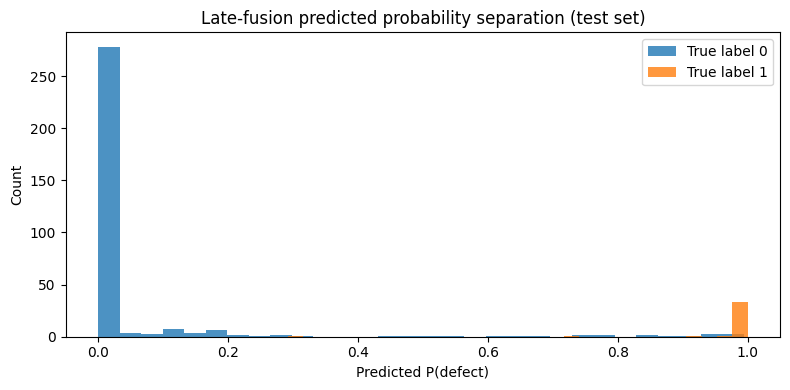

In [ ]:
ys, ps = ys_late, ps_late

plt.figure(figsize=(8, 4))
plt.hist(ps[ys == 0], bins=30, alpha=0.8, label="True label 0")
plt.hist(ps[ys == 1], bins=30, alpha=0.8, label="True label 1")
plt.title("Late-fusion predicted probability separation (test set)")
plt.xlabel("Predicted P(defect)")
plt.ylabel("Count")
plt.legend()
plt.tight_layout()
plt.show()


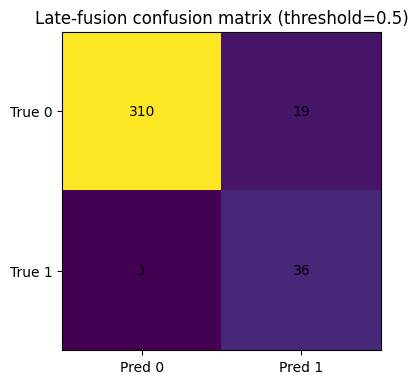

CM:
 [[310  19]
 [  1  36]]


In [ ]:
ys, ps = ys_late, ps_late
pred = (ps > 0.5).astype(int)

cm = confusion_matrix(ys, pred)
plt.figure(figsize=(4, 4))
plt.imshow(cm)
plt.title("Late-fusion confusion matrix (threshold=0.5)")
plt.xticks([0, 1], ["Pred 0", "Pred 1"])
plt.yticks([0, 1], ["True 0", "True 1"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")
plt.tight_layout()
plt.show()

print("CM:\n", cm)


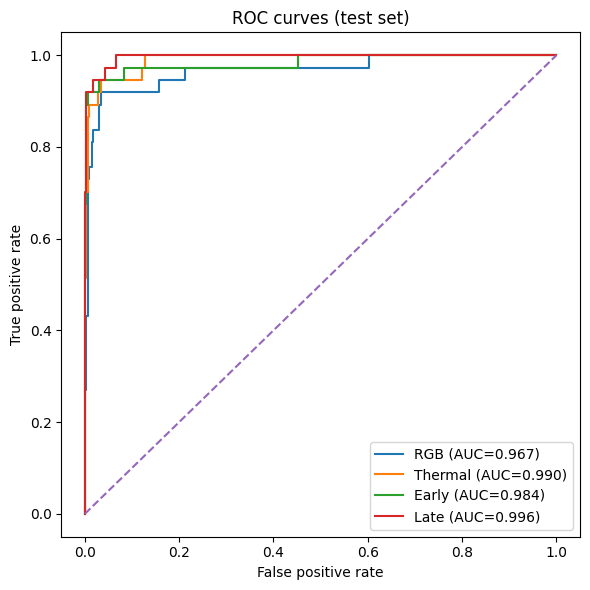

In [ ]:
def plot_roc(ax, ys, ps, name):
    fpr, tpr, _ = roc_curve(ys, ps)
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, label=f"{name} (AUC={roc_auc:.3f})")


fig, ax = plt.subplots(1, 1, figsize=(6, 6))
plot_roc(ax, ys_rgb, ps_rgb, "RGB")
plot_roc(ax, ys_th, ps_th, "Thermal")
plot_roc(ax, ys_early, ps_early, "Early")
plot_roc(ax, ys_late, ps_late, "Late")
ax.plot([0, 1], [0, 1], linestyle="--")
ax.set_title("ROC curves (test set)")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.legend()
plt.tight_layout()
plt.show()

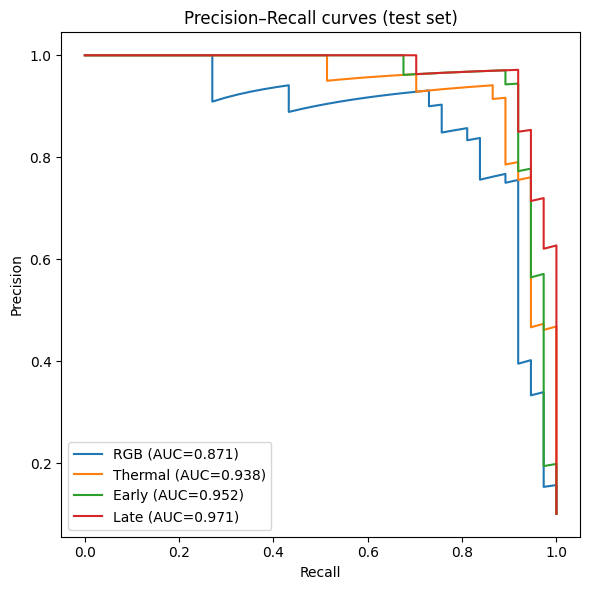

In [ ]:
def plot_pr(ax, ys, ps, name):
    prec, rec, _ = precision_recall_curve(ys, ps)
    pr_auc = auc(rec, prec)
    ax.plot(rec, prec, label=f"{name} (AUC={pr_auc:.3f})")


fig, ax = plt.subplots(1, 1, figsize=(6, 6))
plot_pr(ax, ys_rgb, ps_rgb, "RGB")
plot_pr(ax, ys_th, ps_th, "Thermal")
plot_pr(ax, ys_early, ps_early, "Early")
plot_pr(ax, ys_late, ps_late, "Late")
ax.set_title("Precision–Recall curves (test set)")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend()
plt.tight_layout()
plt.show()

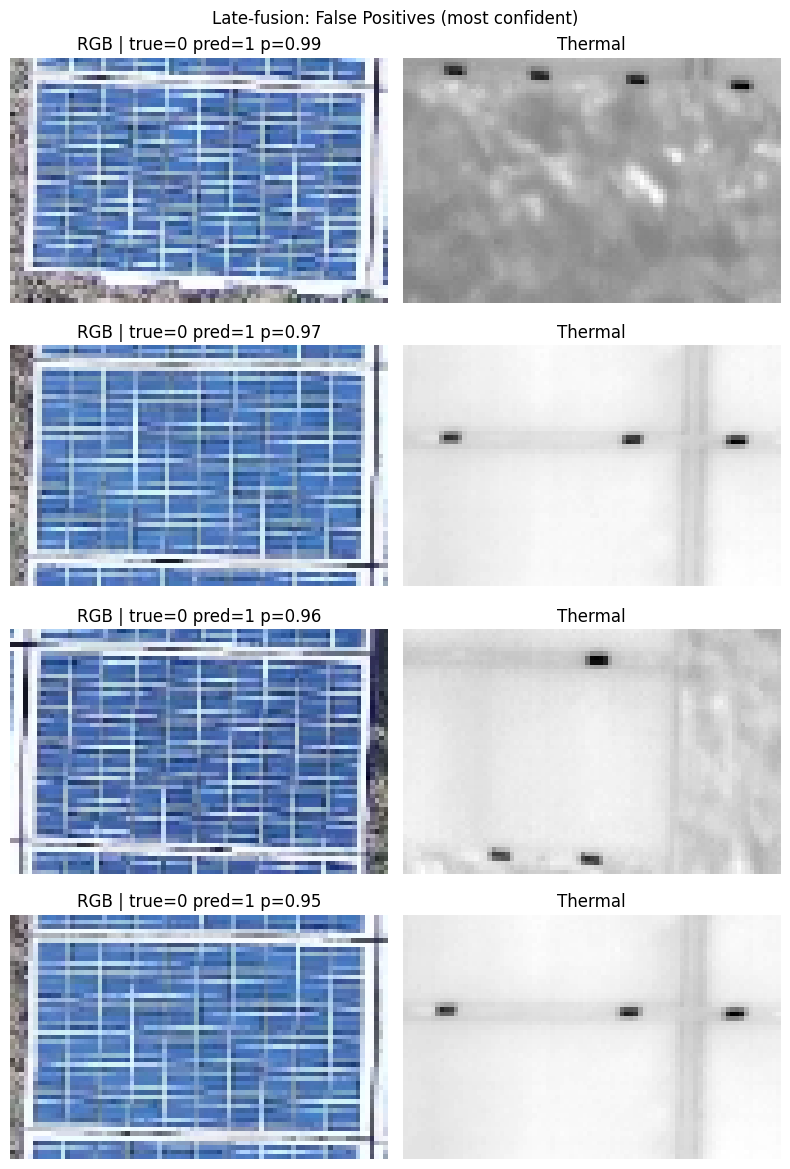

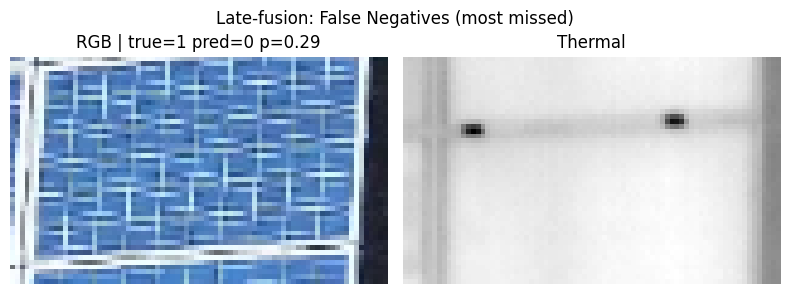

In [ ]:
# We need a dataframe aligned to test_ds rows (module-level). We'll use test_ds.df directly.
test_df = test_ds.df.copy().reset_index(drop=True)

# Get late-fusion probabilities in the SAME order as test_loader iterates (which matches test_ds order if shuffle=False)
# To guarantee alignment, we’ll run a prediction loop over test_loader and store probs sequentially.
ys, ps = predict_on_loader(late_model, test_loader)

test_df["y_true"] = ys
test_df["p_defect"] = ps
test_df["y_pred"] = (test_df["p_defect"] > 0.5).astype(int)

false_pos = (
    test_df[(test_df["y_true"] == 0) & (test_df["y_pred"] == 1)]
    .sort_values("p_defect", ascending=False)
    .head(4)
)
false_neg = (
    test_df[(test_df["y_true"] == 1) & (test_df["y_pred"] == 0)]
    .sort_values("p_defect", ascending=True)
    .head(4)
)


def show_cases(case_df, title):
    n = len(case_df)
    fig, axes = plt.subplots(n, 2, figsize=(8, 3 * n))
    if n == 1:
        axes = np.array([axes])
    for i, row in enumerate(case_df.itertuples(index=False)):
        row_s = case_df.iloc[i]
        rgb, th = load_pair_from_row(row_s)
        show_rgb(axes[i, 0], rgb)
        axes[i, 0].set_title(
            f"RGB | true={int(row_s.y_true)} pred={int(row_s.y_pred)} p={row_s.p_defect:.2f}"
        )
        show_th(axes[i, 1], th)
        axes[i, 1].set_title("Thermal")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


show_cases(false_pos, "Late-fusion: False Positives (most confident)")
show_cases(false_neg, "Late-fusion: False Negatives (most missed)")

# Explainable AI

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F


def _normalize_01(x):
    x = x - x.min()
    return x / (x.max() - x.min() + 1e-8)


class GradCAM:
    """
    Minimal Grad-CAM for a given model and target conv layer.
    Produces a heatmap for class_idx (default = predicted class).
    """

    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None
        self.hook_a = None
        self.hook_g = None

    def _forward_hook(self, module, inp, out):
        self.activations = out

    def _backward_hook(self, module, grad_in, grad_out):
        self.gradients = grad_out[0]

    def __enter__(self):
        self.hook_a = self.target_layer.register_forward_hook(self._forward_hook)
        self.hook_g = self.target_layer.register_full_backward_hook(self._backward_hook)
        return self

    def __exit__(self, exc_type, exc, tb):
        if self.hook_a is not None:
            self.hook_a.remove()
        if self.hook_g is not None:
            self.hook_g.remove()

    def __call__(self, forward_fn, class_idx=None):
        """
        forward_fn: callable that returns logits tensor (1, num_classes)
        """
        self.model.zero_grad(set_to_none=True)
        logits = forward_fn()
        if class_idx is None:
            class_idx = int(torch.argmax(logits, dim=1).item())

        score = logits[:, class_idx].sum()
        score.backward(retain_graph=True)

        A = self.activations  # (1, C, H, W)
        dA = self.gradients  # (1, C, H, W)
        weights = dA.mean(dim=(2, 3), keepdim=True)  # (1, C, 1, 1)
        cam = (weights * A).sum(dim=1, keepdim=False)  # (1, H, W)
        cam = F.relu(cam)[0].detach().cpu().numpy()
        cam = _normalize_01(cam)
        return cam, class_idx, logits.detach().cpu()


def overlay_cam_on_rgb(rgb_uint8, cam_01, alpha=0.45):
    """
    rgb_uint8: HxWx3 in [0..255]
    cam_01: HxW in [0..1]
    """
    cam_resized = cam_01
    if cam_resized.shape != rgb_uint8.shape[:2]:
        cam_resized = np.array(
            torch.nn.functional.interpolate(
                torch.tensor(cam_01)[None, None],
                size=rgb_uint8.shape[:2],
                mode="bilinear",
                align_corners=False,
            )[0, 0]
        )
    cam_img = plt.cm.viridis(cam_resized)[..., :3]  # HxWx3
    rgb = rgb_uint8.astype(np.float32) / 255.0
    out = (1 - alpha) * rgb + alpha * cam_img
    out = np.clip(out, 0, 1)
    return out


def overlay_cam_on_gray(gray_uint8, cam_01, alpha=0.45):
    """
    gray_uint8: HxW in [0..255]
    cam_01: HxW in [0..1]
    """
    g = gray_uint8.astype(np.float32) / 255.0
    g3 = np.repeat(g[..., None], 3, axis=2)
    cam_resized = cam_01
    if cam_resized.shape != gray_uint8.shape:
        cam_resized = np.array(
            torch.nn.functional.interpolate(
                torch.tensor(cam_01)[None, None],
                size=gray_uint8.shape,
                mode="bilinear",
                align_corners=False,
            )[0, 0]
        )
    cam_img = plt.cm.viridis(cam_resized)[..., :3]
    out = (1 - alpha) * g3 + alpha * cam_img
    out = np.clip(out, 0, 1)
    return out

In [ ]:
# Pick a module index from the test set
SAMPLE_IDX = 0

rgb_t, th_t, y = test_ds[SAMPLE_IDX]  # tensors already normalized by dataset transforms
rgb_t = rgb_t.unsqueeze(0).to(DEVICE)
th_t = th_t.unsqueeze(0).to(DEVICE)

# Load raw arrays from npy for visualization
row = test_ds.df.iloc[SAMPLE_IDX]
rgb_raw_bgr = np.load(row["rgb_npy"])
rgb_raw = rgb_raw_bgr[:, :, ::-1].copy()  # RGB
th_raw = np.load(row["thermal_npy"])  # HxW uint8

print("True label:", int(y))
print("rgb tensor:", tuple(rgb_t.shape), "th tensor:", tuple(th_t.shape))
print("rgb raw:", rgb_raw.shape, "th raw:", th_raw.shape)

True label: 0
rgb tensor: (1, 3, 224, 224) th tensor: (1, 1, 224, 224)
rgb raw: (55, 84, 3) th raw: (55, 84)


/var/folders/yl/y5l5x_cj1_v78ybnz0g5dp900000gn/T/ipykernel_73896/651892439.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  prob = torch.softmax(torch.tensor(logits), dim=1)[0,1].item()
/var/folders/yl/y5l5x_cj1_v78ybnz0g5dp900000gn/T/ipykernel_73896/278696583.py:65: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  cam_resized = np.array(


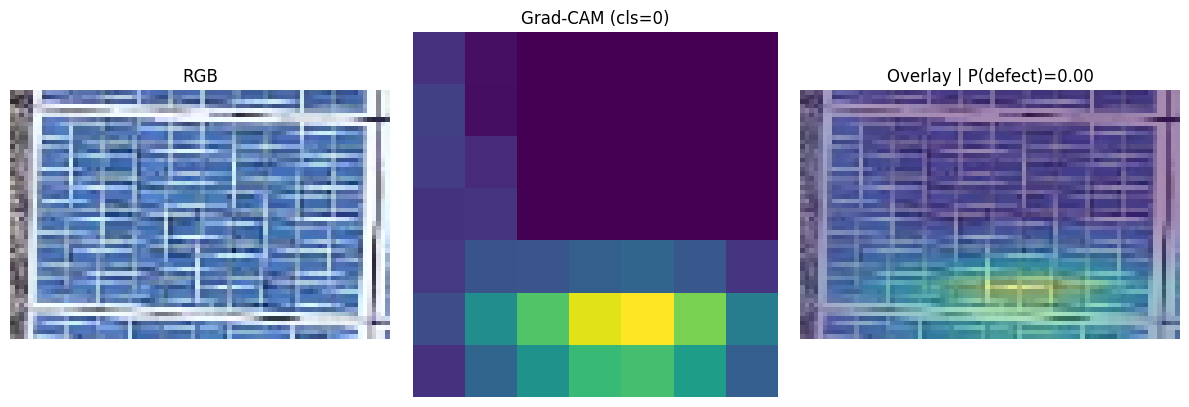

In [ ]:
rgb_model = rgb_model.to(DEVICE).eval()

# ResNet target layer: last block conv output
target_layer = rgb_model.backbone.layer4[-1].conv2

with GradCAM(rgb_model, target_layer) as gc:
    cam, cls, logits = gc(lambda: rgb_model(rgb_t, None), class_idx=None)

prob = torch.softmax(torch.tensor(logits), dim=1)[0, 1].item()
overlay = overlay_cam_on_rgb(rgb_raw, cam, alpha=0.45)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(rgb_raw)
plt.title("RGB")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(cam, cmap="viridis")
plt.title(f"Grad-CAM (cls={cls})")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title(f"Overlay | P(defect)={prob:.2f}")
plt.axis("off")
plt.tight_layout()
plt.show()

/var/folders/yl/y5l5x_cj1_v78ybnz0g5dp900000gn/T/ipykernel_73896/1058240886.py:7: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  prob = torch.softmax(torch.tensor(logits), dim=1)[0,1].item()
/var/folders/yl/y5l5x_cj1_v78ybnz0g5dp900000gn/T/ipykernel_73896/278696583.py:88: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  cam_resized = np.array(


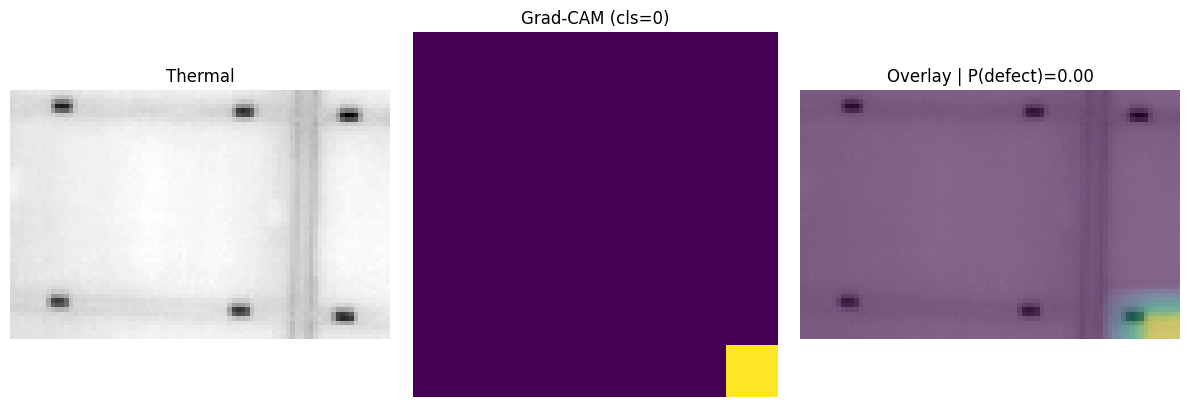

In [ ]:
th_model = th_model.to(DEVICE).eval()
target_layer = th_model.backbone.layer4[-1].conv2

with GradCAM(th_model, target_layer) as gc:
    cam, cls, logits = gc(lambda: th_model(None, th_t), class_idx=None)

prob = torch.softmax(torch.tensor(logits), dim=1)[0, 1].item()
overlay = overlay_cam_on_gray(th_raw, cam, alpha=0.45)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(th_raw, cmap="gray")
plt.title("Thermal")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(cam, cmap="viridis")
plt.title(f"Grad-CAM (cls={cls})")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title(f"Overlay | P(defect)={prob:.2f}")
plt.axis("off")
plt.tight_layout()
plt.show()

/var/folders/yl/y5l5x_cj1_v78ybnz0g5dp900000gn/T/ipykernel_73896/3725430592.py:16: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  prob = torch.softmax(torch.tensor(logits), dim=1)[0,1].item()
/var/folders/yl/y5l5x_cj1_v78ybnz0g5dp900000gn/T/ipykernel_73896/278696583.py:65: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  cam_resized = np.array(
/var/folders/yl/y5l5x_cj1_v78ybnz0g5dp900000gn/T/ipykernel_73896/278696583.py:88: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword argu

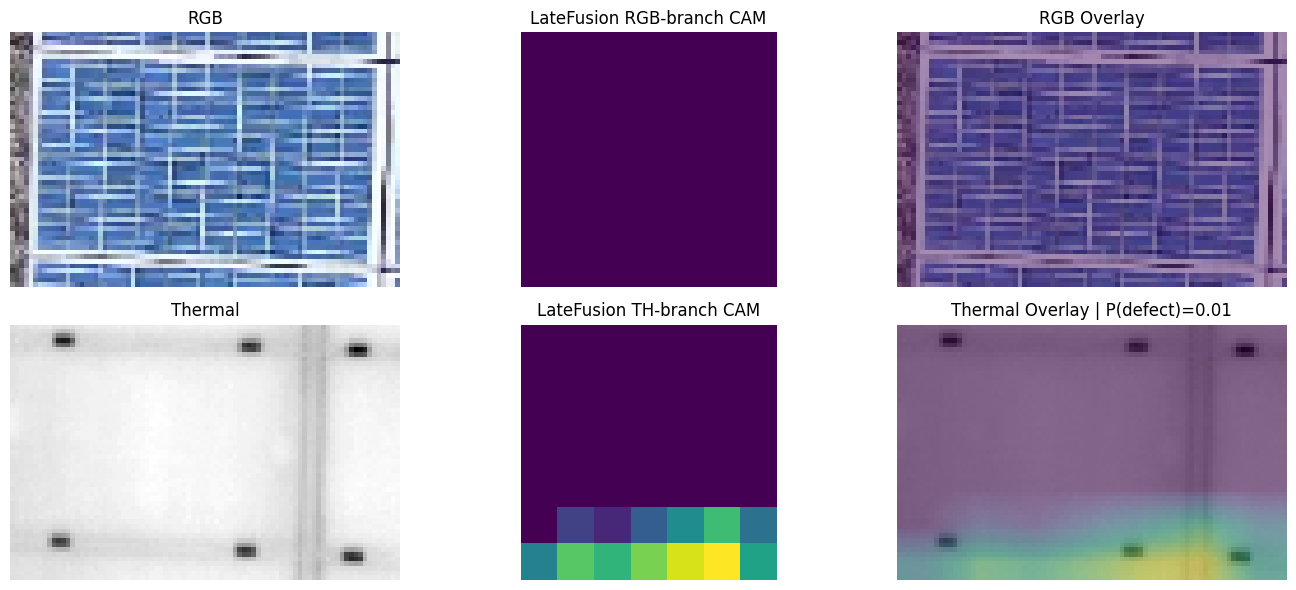

In [ ]:
late_model = late_model.to(DEVICE).eval()

# Target layers inside late fusion branches
rgb_layer = late_model.rgb_net.layer4[-1].conv2
th_layer = late_model.th_net.layer4[-1].conv2

# RGB branch cam
with GradCAM(late_model, rgb_layer) as gc_rgb:
    cam_rgb, cls_rgb, logits = gc_rgb(lambda: late_model(rgb_t, th_t), class_idx=None)

# Thermal branch cam (same class index as final prediction)
pred_cls = int(torch.argmax(logits, dim=1).item())
with GradCAM(late_model, th_layer) as gc_th:
    cam_th, cls_th, _ = gc_th(lambda: late_model(rgb_t, th_t), class_idx=pred_cls)

prob = torch.softmax(torch.tensor(logits), dim=1)[0, 1].item()

overlay_rgb = overlay_cam_on_rgb(rgb_raw, cam_rgb, alpha=0.45)
overlay_th = overlay_cam_on_gray(th_raw, cam_th, alpha=0.45)

plt.figure(figsize=(14, 6))
plt.subplot(2, 3, 1)
plt.imshow(rgb_raw)
plt.title("RGB")
plt.axis("off")
plt.subplot(2, 3, 2)
plt.imshow(cam_rgb, cmap="viridis")
plt.title("LateFusion RGB-branch CAM")
plt.axis("off")
plt.subplot(2, 3, 3)
plt.imshow(overlay_rgb)
plt.title("RGB Overlay")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(th_raw, cmap="gray")
plt.title("Thermal")
plt.axis("off")
plt.subplot(2, 3, 5)
plt.imshow(cam_th, cmap="viridis")
plt.title("LateFusion TH-branch CAM")
plt.axis("off")
plt.subplot(2, 3, 6)
plt.imshow(overlay_th)
plt.title(f"Thermal Overlay | P(defect)={prob:.2f}")
plt.axis("off")

plt.tight_layout()
plt.show()

# SHAP

In [ ]:
!pip install shap


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 554.9/554.9 kB 10.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 16.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.2/37.2 MB 16.7 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [shap]4/5 [shap]]te]


In [ ]:
import shap
import numpy as np
import torch
import matplotlib.pyplot as plt

In [ ]:
@torch.no_grad()
def get_latefusion_embeddings(late_model, rgb_batch, th_batch):
    late_model.eval()
    z_rgb = late_model.proj_rgb(late_model.rgb_net(rgb_batch))
    z_th = late_model.proj_th(late_model.th_net(th_batch))
    z = torch.cat([z_rgb, z_th], dim=1)
    return z.detach().cpu().numpy()

In [ ]:
@torch.no_grad()
def head_predict_proba_from_embedding(late_model, z_np):
    z_np = np.asarray(z_np)
    if z_np.ndim == 1:
        z_np = z_np[None, :]

    z = torch.tensor(z_np, dtype=torch.float32, device=DEVICE)
    logits = late_model.head(z)  # (N,2)
    prob1 = torch.softmax(logits, dim=1)[:, 1]
    out = prob1.detach().cpu().numpy().astype(np.float64)
    return out.reshape(-1, 1)  # (N,1)

In [ ]:
BG_N = 64
EXPLAIN_N = 8
NEED = BG_N + EXPLAIN_N

rgb_list, th_list, y_list = [], [], []
count = 0

for rgb_b, th_b, y_b in test_loader:
    rgb_list.append(rgb_b)
    th_list.append(th_b)
    y_list.append(y_b)
    count += rgb_b.size(0)
    if count >= NEED:
        break

rgb_all = torch.cat(rgb_list, dim=0).to(DEVICE)
th_all = torch.cat(th_list, dim=0).to(DEVICE)
y_all = torch.cat(y_list, dim=0).cpu().numpy()

print("Collected samples:", rgb_all.shape[0])

Collected samples: 128


In [ ]:
z_bg = get_latefusion_embeddings(late_model, rgb_all[:BG_N], th_all[:BG_N])
z_explain = get_latefusion_embeddings(
    late_model, rgb_all[BG_N : BG_N + EXPLAIN_N], th_all[BG_N : BG_N + EXPLAIN_N]
)
y_explain = y_all[BG_N : BG_N + EXPLAIN_N]

print("z_bg:", z_bg.shape)
print("z_explain:", z_explain.shape)

z_bg: (64, 512)
z_explain: (8, 512)


In [ ]:
p_bg = head_predict_proba_from_embedding(late_model, z_bg[:5])
p_ex = head_predict_proba_from_embedding(late_model, z_explain[:5])

print("pred(bg):", p_bg.shape, p_bg.min(), p_bg.max())
print("pred(ex):", p_ex.shape, p_ex.min(), p_ex.max())

pred(bg): (5, 1) 0.006830609403550625 0.9638312458992004
pred(ex): (5, 1) 9.805358786252327e-06 0.9998493194580078


In [ ]:
explainer = shap.KernelExplainer(
    lambda z: head_predict_proba_from_embedding(late_model, z), z_bg
)

shap_values = explainer.shap_values(z_explain, nsamples=200)

# Normalize to (N, D)
if isinstance(shap_values, list):
    shap_values = shap_values[0]
shap_values = np.array(shap_values)
if shap_values.ndim == 3:
    shap_values = shap_values[0]

print("SHAP values shape:", shap_values.shape)

100%|██████████| 8/8 [00:00<00:00, 23.01it/s]

SHAP values shape: (512, 1)


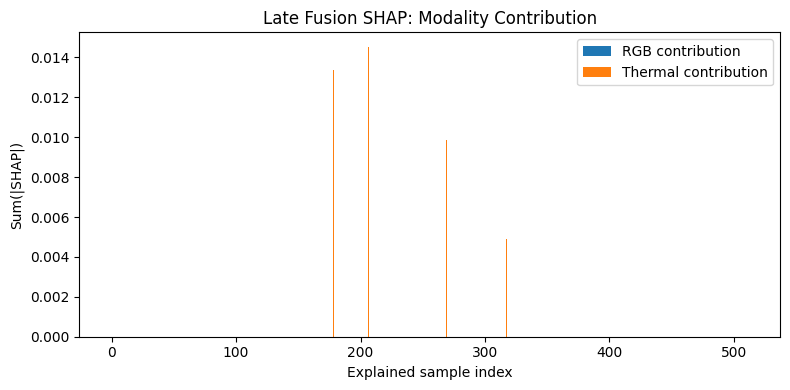

Sample 0: RGB 0.0% | Thermal 0.0%
Sample 1: RGB 0.0% | Thermal 0.0%
Sample 2: RGB 0.0% | Thermal 0.0%
Sample 3: RGB 0.0% | Thermal 0.0%
Sample 4: RGB 0.0% | Thermal 0.0%
Sample 5: RGB 0.0% | Thermal 0.0%
Sample 6: RGB 0.0% | Thermal 0.0%
Sample 7: RGB 0.0% | Thermal 0.0%
Sample 8: RGB 0.0% | Thermal 0.0%
Sample 9: RGB 0.0% | Thermal 0.0%
Sample 10: RGB 0.0% | Thermal 0.0%
Sample 11: RGB 0.0% | Thermal 0.0%
Sample 12: RGB 0.0% | Thermal 0.0%
Sample 13: RGB 0.0% | Thermal 0.0%
Sample 14: RGB 0.0% | Thermal 0.0%
Sample 15: RGB 0.0% | Thermal 0.0%
Sample 16: RGB 0.0% | Thermal 0.0%
Sample 17: RGB 0.0% | Thermal 0.0%
Sample 18: RGB 0.0% | Thermal 0.0%
Sample 19: RGB 0.0% | Thermal 0.0%
Sample 20: RGB 0.0% | Thermal 0.0%
Sample 21: RGB 0.0% | Thermal 0.0%
Sample 22: RGB 0.0% | Thermal 0.0%
Sample 23: RGB 0.0% | Thermal 0.0%
Sample 24: RGB 0.0% | Thermal 0.0%
Sample 25: RGB 0.0% | Thermal 0.0%
Sample 26: RGB 0.0% | Thermal 0.0%
Sample 27: RGB 0.0% | Thermal 0.0%
Sample 28: RGB 0.0% | Thermal 

In [ ]:
D = shap_values.shape[1]
half = D // 2

rgb_contrib = np.abs(shap_values[:, :half]).sum(axis=1)
th_contrib = np.abs(shap_values[:, half:]).sum(axis=1)

plt.figure(figsize=(8, 4))
x = np.arange(len(rgb_contrib))
plt.bar(x - 0.2, rgb_contrib, width=0.4, label="RGB contribution")
plt.bar(x + 0.2, th_contrib, width=0.4, label="Thermal contribution")
plt.title("Late Fusion SHAP: Modality Contribution")
plt.xlabel("Explained sample index")
plt.ylabel("Sum(|SHAP|)")
plt.legend()
plt.tight_layout()
plt.show()

for i in range(len(rgb_contrib)):
    tot = rgb_contrib[i] + th_contrib[i] + 1e-8
    print(
        f"Sample {i}: RGB {rgb_contrib[i] / tot:.1%} | Thermal {th_contrib[i] / tot:.1%}"
    )

# GRADCAM AGAIN (Just to Test)

In [ ]:
import torch.nn.functional as F


class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.layer = target_layer
        self.activations = None
        self.gradients = None

        self.layer.register_forward_hook(self._forward)
        self.layer.register_full_backward_hook(self._backward)

    def _forward(self, module, inp, out):
        self.activations = out

    def _backward(self, module, grad_in, grad_out):
        self.gradients = grad_out[0]

    def __call__(self, forward_fn, class_idx=None):
        self.model.zero_grad()
        logits = forward_fn()
        if class_idx is None:
            class_idx = logits.argmax(dim=1).item()

        score = logits[:, class_idx].sum()
        score.backward()

        w = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = (w * self.activations).sum(dim=1)
        cam = F.relu(cam)[0].detach().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() + 1e-8)
        return cam

In [ ]:
IDX = 0
rgb_t, th_t, y = test_ds[IDX]
rgb_t = rgb_t.unsqueeze(0).to(DEVICE)
th_t = th_t.unsqueeze(0).to(DEVICE)

row = test_ds.df.iloc[IDX]
rgb_raw = np.load(row["rgb_npy"])[:, :, ::-1]
th_raw = np.load(row["thermal_npy"])

print("True label:", int(y))

True label: 0


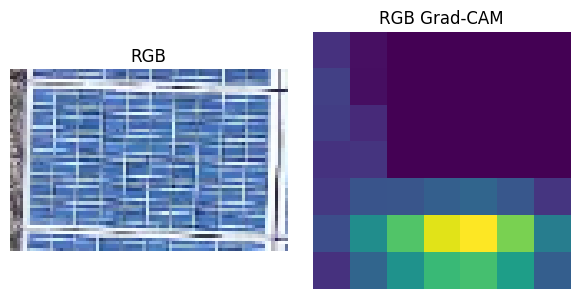

In [ ]:
rgb_model.eval()
cam_rgb = GradCAM(rgb_model, rgb_model.backbone.layer4[-1].conv2)
heat = cam_rgb(lambda: rgb_model(rgb_t, None))

plt.figure(figsize=(6, 3))
plt.subplot(1, 2, 1)
plt.imshow(rgb_raw)
plt.title("RGB")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(heat, cmap="viridis")
plt.title("RGB Grad-CAM")
plt.axis("off")
plt.tight_layout()
plt.show()

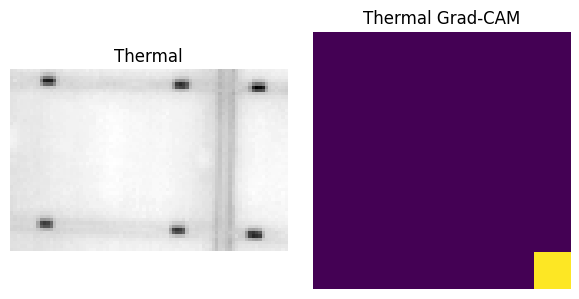

In [ ]:
th_model.eval()
cam_th = GradCAM(th_model, th_model.backbone.layer4[-1].conv2)
heat = cam_th(lambda: th_model(None, th_t))

plt.figure(figsize=(6, 3))
plt.subplot(1, 2, 1)
plt.imshow(th_raw, cmap="gray")
plt.title("Thermal")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(heat, cmap="viridis")
plt.title("Thermal Grad-CAM")
plt.axis("off")
plt.tight_layout()
plt.show()

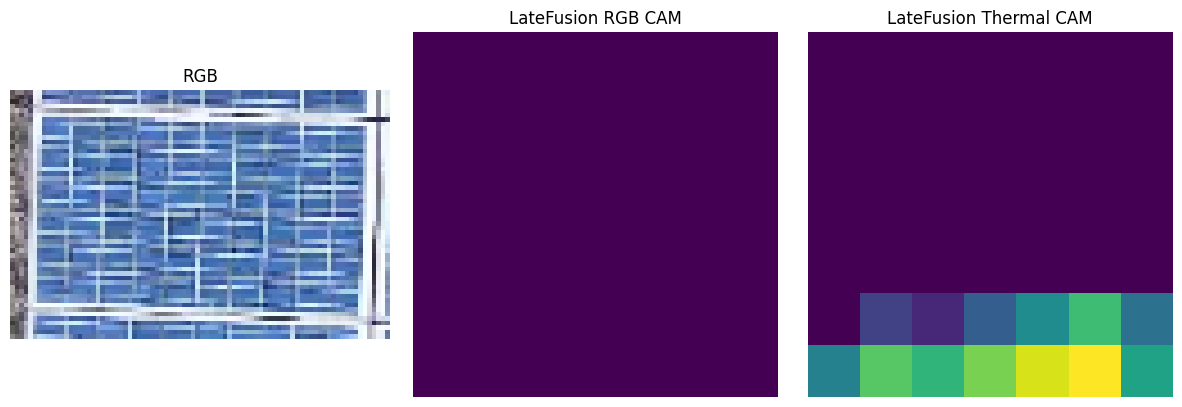

In [ ]:
late_model.eval()

cam_rgb = GradCAM(late_model, late_model.rgb_net.layer4[-1].conv2)
cam_th = GradCAM(late_model, late_model.th_net.layer4[-1].conv2)

heat_rgb = cam_rgb(lambda: late_model(rgb_t, th_t))
heat_th = cam_th(lambda: late_model(rgb_t, th_t))

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(rgb_raw)
plt.title("RGB")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(heat_rgb, cmap="viridis")
plt.title("LateFusion RGB CAM")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(heat_th, cmap="viridis")
plt.title("LateFusion Thermal CAM")
plt.axis("off")
plt.tight_layout()
plt.show()

# Modality Ablation (Very Strong Explainability)

What this shows:

“For each test sample, we remove RGB or Thermal information and observe how much the prediction confidence drops. This tells us which modality the model actually relies on.”

This complements SHAP beautifully.

In [ ]:
@torch.no_grad()
def predict_prob_late(model, rgb, th, mask_rgb=False, mask_th=False):
    """
    Returns probability of class 1
    """
    model.eval()

    if mask_rgb:
        rgb = torch.zeros_like(rgb)
    if mask_th:
        th = torch.zeros_like(th)

    logits = model(rgb, th)
    prob = torch.softmax(logits, dim=1)[:, 1]
    return prob.detach().cpu().numpy()

In [ ]:
rgb_drop = []
th_drop = []

late_model.eval()

for rgb, th, y in test_loader:
    rgb = rgb.to(DEVICE)
    th = th.to(DEVICE)

    p_full = predict_prob_late(late_model, rgb, th)
    p_no_rgb = predict_prob_late(late_model, rgb, th, mask_rgb=True)
    p_no_th = predict_prob_late(late_model, rgb, th, mask_th=True)

    rgb_drop.extend(p_full - p_no_rgb)
    th_drop.extend(p_full - p_no_th)

rgb_drop = np.array(rgb_drop)
th_drop = np.array(th_drop)

In [ ]:
print(f"Average drop when RGB removed:     {rgb_drop.mean():.4f}")
print(f"Average drop when Thermal removed: {th_drop.mean():.4f}")

print(f"Median drop RGB: {np.median(rgb_drop):.4f}")
print(f"Median drop TH:  {np.median(th_drop):.4f}")

Average drop when RGB removed:     -0.0171
Average drop when Thermal removed: 0.1569
Median drop RGB: -0.0000
Median drop TH:  0.0012


/var/folders/yl/y5l5x_cj1_v78ybnz0g5dp900000gn/T/ipykernel_73896/3626552705.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([rgb_drop, th_drop], labels=["RGB removed", "Thermal removed"])


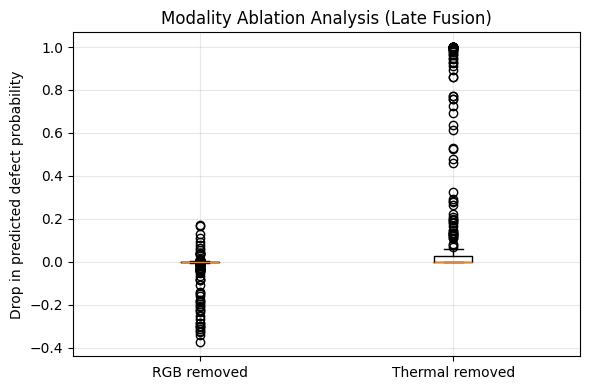

In [ ]:
plt.figure(figsize=(6, 4))
plt.boxplot([rgb_drop, th_drop], labels=["RGB removed", "Thermal removed"])
plt.ylabel("Drop in predicted defect probability")
plt.title("Modality Ablation Analysis (Late Fusion)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Calibration and Reliability (Trustworthiness)

Why this matters:

My model outputs probabilities. Calibration answers:

“If the model says 80% defect, is it actually correct ~80% of the time?”

This is huge for inspection systems.

In [ ]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

y_true = []
y_prob = []

late_model.eval()

for rgb, th, y in test_loader:
    rgb = rgb.to(DEVICE)
    th = th.to(DEVICE)

    prob = predict_prob_late(late_model, rgb, th)
    y_prob.extend(prob)
    y_true.extend(y.numpy())

y_true = np.array(y_true)
y_prob = np.array(y_prob)

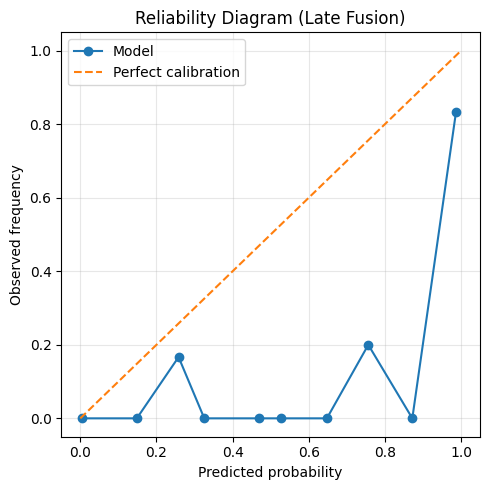

In [ ]:
prob_true, prob_pred = calibration_curve(y_true, y_prob, n_bins=10, strategy="uniform")

plt.figure(figsize=(5, 5))
plt.plot(prob_pred, prob_true, marker="o", label="Model")
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
plt.xlabel("Predicted probability")
plt.ylabel("Observed frequency")
plt.title("Reliability Diagram (Late Fusion)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
brier = brier_score_loss(y_true, y_prob)
print(f"Brier score (lower is better): {brier:.4f}")

Brier score (lower is better): 0.0401


How to explain ALL explainability briefly?

A summarization like this:

• Grad-CAM shows where the model looks in RGB and Thermal images
• SHAP (embedding-level) quantifies how much each modality contributes
• Modality ablation proves the fusion model truly uses both modalities
• Calibration analysis shows the predictions are reliable and actionable

That’s a complete, modern XAI story.

# LIME

In [ ]:
!pip install lime scikit-image


In [ ]:
from lime import lime_image
from skimage.segmentation import mark_boundaries
import numpy as np
import matplotlib.pyplot as plt
import torch

In [ ]:
USE_NORMALIZE = False

# Common ImageNet normalization (ONLY if normalized RGB like ImageNet)
RGB_MEAN = (0.485, 0.456, 0.406)
RGB_STD = (0.229, 0.224, 0.225)

# Thermal: if normalized thermal to mean/std, put it here. Otherwise leave.
TH_MEAN = (0.5,)
TH_STD = (0.5,)


def normalize_rgb_tensor(x_chw):
    # x_chw: torch tensor C,H,W in [0,1]
    if not USE_NORMALIZE:
        return x_chw
    mean = torch.tensor(RGB_MEAN, dtype=x_chw.dtype)[:, None, None]
    std = torch.tensor(RGB_STD, dtype=x_chw.dtype)[:, None, None]
    return (x_chw - mean) / std


def normalize_th_tensor(x_1hw):
    # x_1hw: torch tensor 1,H,W in [0,1]
    if not USE_NORMALIZE:
        return x_1hw
    mean = torch.tensor(TH_MEAN, dtype=x_1hw.dtype)[:, None, None]
    std = torch.tensor(TH_STD, dtype=x_1hw.dtype)[:, None, None]
    return (x_1hw - mean) / std

In [ ]:
def load_raw_pair_from_test(idx):
    row = test_ds.df.iloc[idx]
    rgb_bgr = np.load(row["rgb_npy"])  # H,W,3 BGR uint8
    rgb = rgb_bgr[:, :, ::-1].copy()  # -> RGB uint8
    th = np.load(row["thermal_npy"]).copy()  # H,W uint8
    y = int(row["label"]) if "label" in row else None
    return rgb, th, y

In [ ]:
def rgb_np_to_tensor(rgb_uint8):
    """
    rgb_uint8: (H,W,3) RGB uint8
    returns: (1,3,H,W) torch float
    """
    x = rgb_uint8.astype(np.float32) / 255.0
    x = torch.tensor(x).permute(2, 0, 1)  # 3,H,W
    x = normalize_rgb_tensor(x)
    return x.unsqueeze(0).to(DEVICE)


def th_np_to_tensor(th_uint8):
    """
    th_uint8: (H,W) uint8
    returns: (1,1,H,W) torch float
    """
    x = th_uint8.astype(np.float32) / 255.0
    x = torch.tensor(x)[None, :, :]  # 1,H,W
    x = normalize_th_tensor(x)
    return x.unsqueeze(0).to(DEVICE)

In [ ]:
def lime_predict_rgbonly(images_np):
    """
    images_np: (N,H,W,3) RGB uint8
    returns: (N,2) probabilities
    """
    rgb_model.eval()
    probs_all = []

    with torch.no_grad():
        for img in images_np:
            rgb_t = rgb_np_to_tensor(img)  # (1,3,H,W)
            logits = rgb_model(rgb_t, None)  # (1,2)
            probs = torch.softmax(logits, dim=1).cpu().numpy()[0]
            probs_all.append(probs)

    return np.stack(probs_all, axis=0)

100%|██████████| 1500/1500 [00:09<00:00, 161.11it/s]


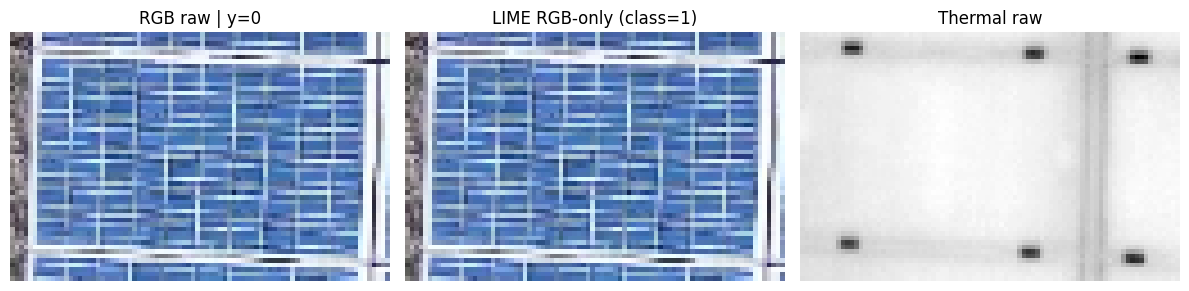

In [ ]:
IDX = 0  # can be changed
NUM_SAMPLES = 1500  # can be increased to 3000 for more stability

rgb_raw, th_raw, y = load_raw_pair_from_test(IDX)

explainer = lime_image.LimeImageExplainer()
explanation = explainer.explain_instance(
    rgb_raw, lime_predict_rgbonly, top_labels=2, hide_color=0, num_samples=NUM_SAMPLES
)

# Explain class=1 (defect)
temp, mask = explanation.get_image_and_mask(
    label=1, positive_only=True, num_features=10, hide_rest=False
)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(rgb_raw)
plt.title(f"RGB raw | y={y}")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(mark_boundaries(temp / 255.0, mask))
plt.title("LIME RGB-only (class=1)")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(th_raw, cmap="gray")
plt.title("Thermal raw")
plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
def lime_predict_thermalonly(images_np):
    """
    images_np: (N,H,W,3) uint8
    We treat it as repeated grayscale; convert to single-channel for model.
    returns: (N,2) probabilities
    """
    th_model.eval()
    probs_all = []

    with torch.no_grad():
        for img3 in images_np:
            # convert 3ch to 1ch grayscale (take channel 0)
            th_uint8 = img3[:, :, 0]
            th_t = th_np_to_tensor(th_uint8)  # (1,1,H,W)
            logits = th_model(None, th_t)  # (1,2)
            probs = torch.softmax(logits, dim=1).cpu().numpy()[0]
            probs_all.append(probs)

    return np.stack(probs_all, axis=0)

100%|██████████| 1500/1500 [00:09<00:00, 165.11it/s]


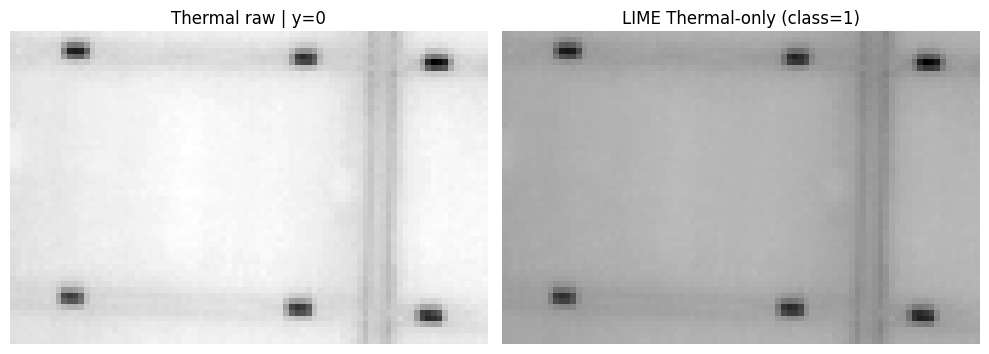

In [ ]:
IDX = 0
NUM_SAMPLES = 1500

rgb_raw, th_raw, y = load_raw_pair_from_test(IDX)

# LIME wants 3-channel image => repeat thermal to 3 channels
th3 = np.repeat(th_raw[:, :, None], 3, axis=2)

explainer = lime_image.LimeImageExplainer()
explanation = explainer.explain_instance(
    th3, lime_predict_thermalonly, top_labels=2, hide_color=0, num_samples=NUM_SAMPLES
)

temp, mask = explanation.get_image_and_mask(
    label=1, positive_only=True, num_features=10, hide_rest=False
)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(th_raw, cmap="gray")
plt.title(f"Thermal raw | y={y}")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(mark_boundaries(temp / 255.0, mask))
plt.title("LIME Thermal-only (class=1)")
plt.axis("off")
plt.tight_layout()
plt.show()

100%|██████████| 1500/1500 [00:17<00:00, 83.61it/s]


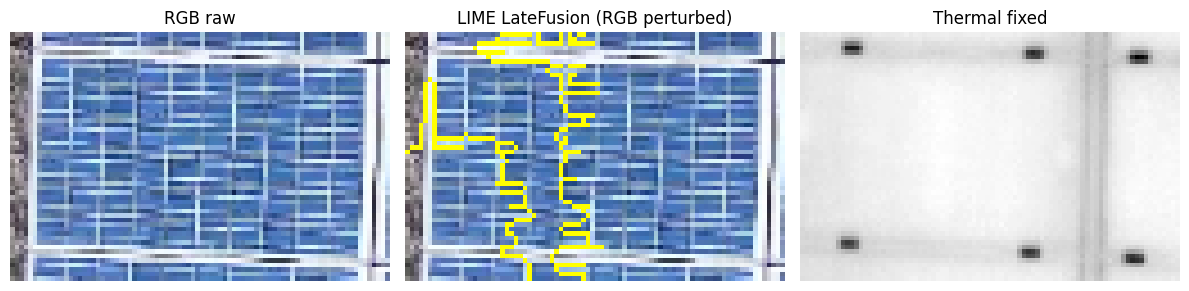

In [ ]:
def make_lime_predict_late_rgbfixed(th_fixed_uint8):
    th_fixed_t = th_np_to_tensor(th_fixed_uint8)

    def predict(images_np):
        late_model.eval()
        probs_all = []
        with torch.no_grad():
            for img in images_np:
                rgb_t = rgb_np_to_tensor(img)
                logits = late_model(rgb_t, th_fixed_t)
                probs = torch.softmax(logits, dim=1).cpu().numpy()[0]
                probs_all.append(probs)
        return np.stack(probs_all, axis=0)

    return predict


IDX = 0
NUM_SAMPLES = 1500

rgb_raw, th_raw, y = load_raw_pair_from_test(IDX)

predict_fn = make_lime_predict_late_rgbfixed(th_raw)

explainer = lime_image.LimeImageExplainer()
explanation = explainer.explain_instance(
    rgb_raw, predict_fn, top_labels=2, hide_color=0, num_samples=NUM_SAMPLES
)

temp, mask = explanation.get_image_and_mask(
    label=1, positive_only=True, num_features=10, hide_rest=False
)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(rgb_raw)
plt.title("RGB raw")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(mark_boundaries(temp / 255.0, mask))
plt.title("LIME LateFusion (RGB perturbed)")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(th_raw, cmap="gray")
plt.title("Thermal fixed")
plt.axis("off")
plt.tight_layout()
plt.show()

100%|██████████| 1500/1500 [00:19<00:00, 77.58it/s]


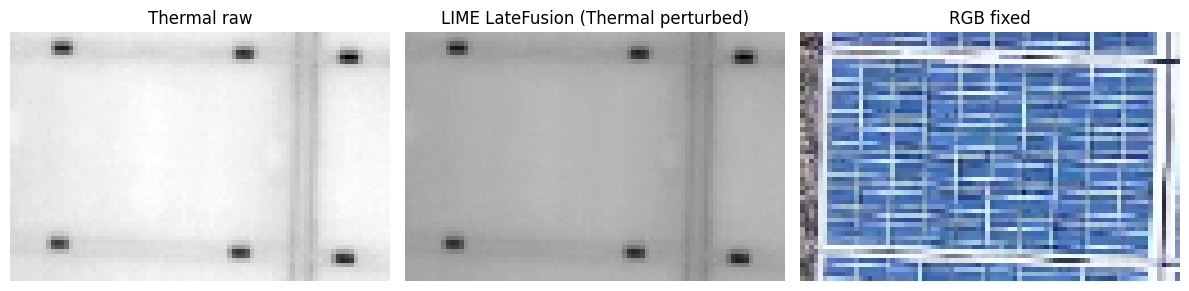

In [ ]:
def make_lime_predict_late_thfixed(rgb_fixed_uint8):
    rgb_fixed_t = rgb_np_to_tensor(rgb_fixed_uint8)

    def predict(images_np):
        late_model.eval()
        probs_all = []
        with torch.no_grad():
            for img3 in images_np:
                th_uint8 = img3[:, :, 0]
                th_t = th_np_to_tensor(th_uint8)
                logits = late_model(rgb_fixed_t, th_t)
                probs = torch.softmax(logits, dim=1).cpu().numpy()[0]
                probs_all.append(probs)
        return np.stack(probs_all, axis=0)

    return predict


IDX = 0
NUM_SAMPLES = 1500

rgb_raw, th_raw, y = load_raw_pair_from_test(IDX)
th3 = np.repeat(th_raw[:, :, None], 3, axis=2)

predict_fn = make_lime_predict_late_thfixed(rgb_raw)

explainer = lime_image.LimeImageExplainer()
explanation = explainer.explain_instance(
    th3, predict_fn, top_labels=2, hide_color=0, num_samples=NUM_SAMPLES
)

temp, mask = explanation.get_image_and_mask(
    label=1, positive_only=True, num_features=10, hide_rest=False
)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(th_raw, cmap="gray")
plt.title("Thermal raw")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(mark_boundaries(temp / 255.0, mask))
plt.title("LIME LateFusion (Thermal perturbed)")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(rgb_raw)
plt.title("RGB fixed")
plt.axis("off")
plt.tight_layout()
plt.show()

# Global Modality Contribution Map

In [ ]:
@torch.no_grad()
def predict_prob_late(model, rgb, th, mask_rgb=False, mask_th=False):
    model.eval()
    if mask_rgb:
        rgb = torch.zeros_like(rgb)
    if mask_th:
        th = torch.zeros_like(th)
    logits = model(rgb, th)
    prob = torch.softmax(logits, dim=1)[:, 1]
    return prob.detach().cpu().numpy()


rows = []

late_model.eval()
idx_counter = 0

for rgb, th, y in test_loader:
    rgb = rgb.to(DEVICE)
    th = th.to(DEVICE)
    y = y.cpu().numpy()

    p_full = predict_prob_late(late_model, rgb, th)
    p_no_rgb = predict_prob_late(late_model, rgb, th, mask_rgb=True)
    p_no_th = predict_prob_late(late_model, rgb, th, mask_th=True)

    rgb_drop = p_full - p_no_rgb
    th_drop = p_full - p_no_th

    for i in range(len(y)):
        rows.append(
            {
                "test_index": idx_counter,
                "label": int(y[i]),
                "p_full": float(p_full[i]),
                "rgb_drop": float(rgb_drop[i]),
                "th_drop": float(th_drop[i]),
                "confidence": float(abs(p_full[i] - 0.5) * 2.0),  # 0..1
            }
        )
        idx_counter += 1

ablate_df = pd.DataFrame(rows)
ablate_df.head(), len(ablate_df)


(   test_index  label    p_full  rgb_drop   th_drop  confidence
 0           0      0  0.006965  0.002553  0.006965    0.986071
 1           1      0  0.127115 -0.209973  0.127115    0.745770
 2           2      0  0.459672 -0.161285  0.459672    0.080656
 3           3      0  0.006831 -0.012103  0.006831    0.986339
 4           4      0  0.963831  0.039474  0.963831    0.927663,
 366)

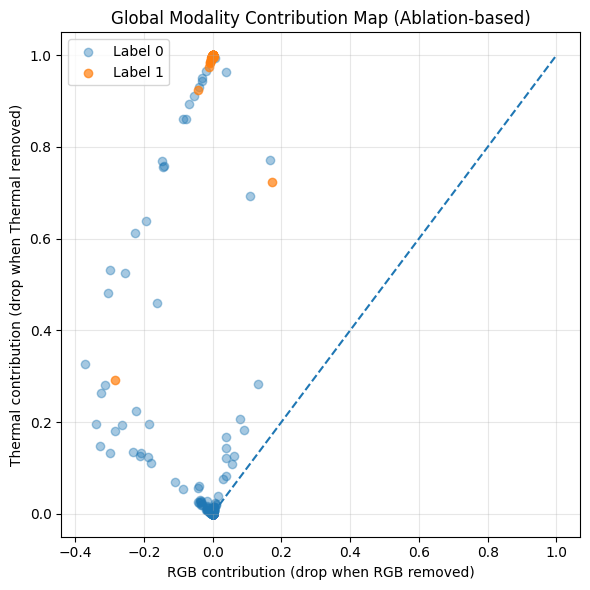

Mean RGB drop: -0.01713521289980897
Mean TH drop:  0.15687803789245647


In [ ]:
plt.figure(figsize=(6, 6))

pos = ablate_df[ablate_df["label"] == 1]
neg = ablate_df[ablate_df["label"] == 0]

plt.scatter(neg["rgb_drop"], neg["th_drop"], alpha=0.4, label="Label 0")
plt.scatter(pos["rgb_drop"], pos["th_drop"], alpha=0.7, label="Label 1")

mx = max(ablate_df["rgb_drop"].max(), ablate_df["th_drop"].max())
plt.plot([0, mx], [0, mx], linestyle="--")  # diagonal

plt.xlabel("RGB contribution (drop when RGB removed)")
plt.ylabel("Thermal contribution (drop when Thermal removed)")
plt.title("Global Modality Contribution Map (Ablation-based)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Mean RGB drop:", ablate_df["rgb_drop"].mean())
print("Mean TH drop: ", ablate_df["th_drop"].mean())

In [ ]:
ablate_df["dominance"] = ablate_df["th_drop"] - ablate_df["rgb_drop"]

print("Thermal-dominant count:", (ablate_df["dominance"] > 0).sum())
print("RGB-dominant count:    ", (ablate_df["dominance"] < 0).sum())

top_th = ablate_df.sort_values("dominance", ascending=False).head(6)
top_rgb = ablate_df.sort_values("dominance", ascending=True).head(6)

(
    top_th[["test_index", "label", "p_full", "rgb_drop", "th_drop", "dominance"]],
    top_rgb[["test_index", "label", "p_full", "rgb_drop", "th_drop", "dominance"]],
)

Thermal-dominant count: 358
RGB-dominant count:     8


(     test_index  label    p_full  rgb_drop   th_drop  dominance
 44           44      1  0.999909 -0.000005  0.999909   0.999914
 68           68      1  0.999849 -0.000062  0.999849   0.999911
 52           52      1  0.999820 -0.000061  0.999820   0.999882
 147         147      1  0.999773 -0.000103  0.999773   0.999876
 63           63      1  0.999948  0.000076  0.999948   0.999872
 84           84      1  0.999792 -0.000063  0.999792   0.999855,
      test_index  label        p_full      rgb_drop       th_drop     dominance
 246         246      0  3.172430e-10  3.172155e-10  5.027589e-11 -2.669396e-10
 309         309      0  1.518078e-09  1.517880e-09  1.344984e-09 -1.728961e-10
 286         286      0  1.664594e-10  1.664367e-10 -3.380268e-12 -1.698169e-10
 209         209      0  8.127037e-10  8.125858e-10  6.549238e-10 -1.576620e-10
 288         288      0  2.830185e-08  2.829770e-08  2.815206e-08 -1.456399e-10
 317         317      0  2.820541e-10  2.820028e-10  1.542511e-1

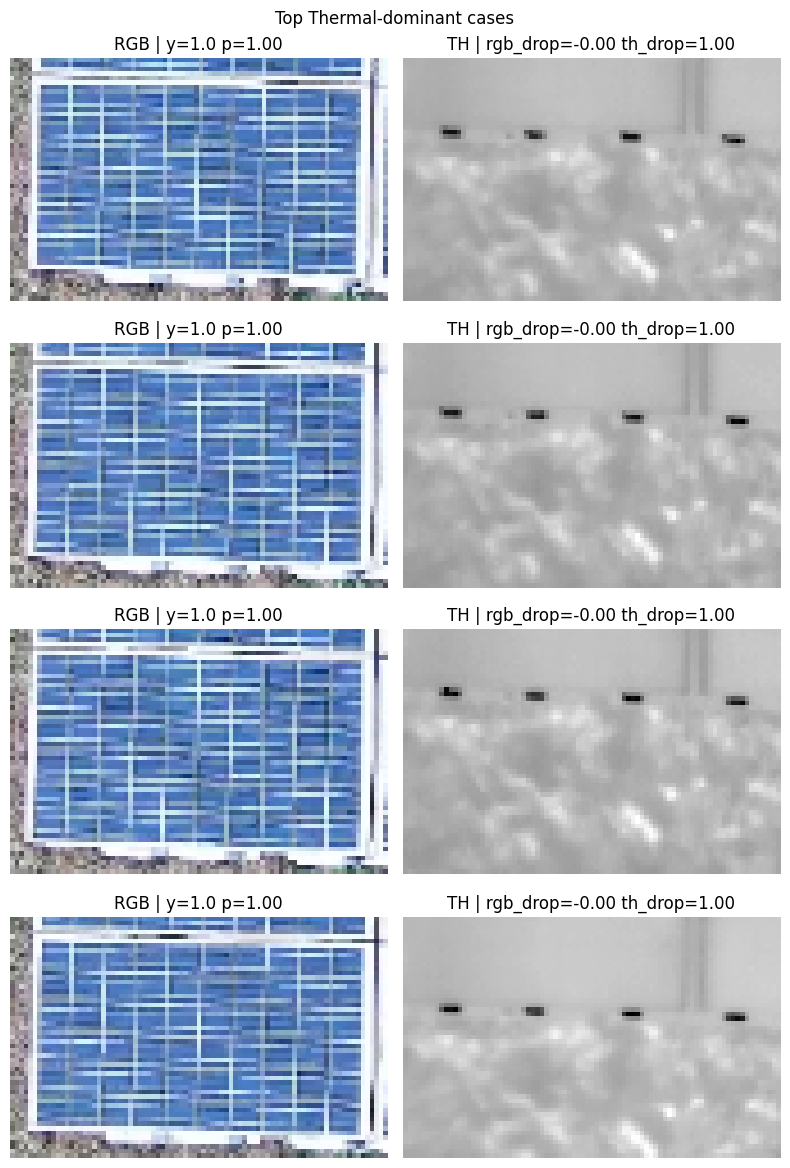

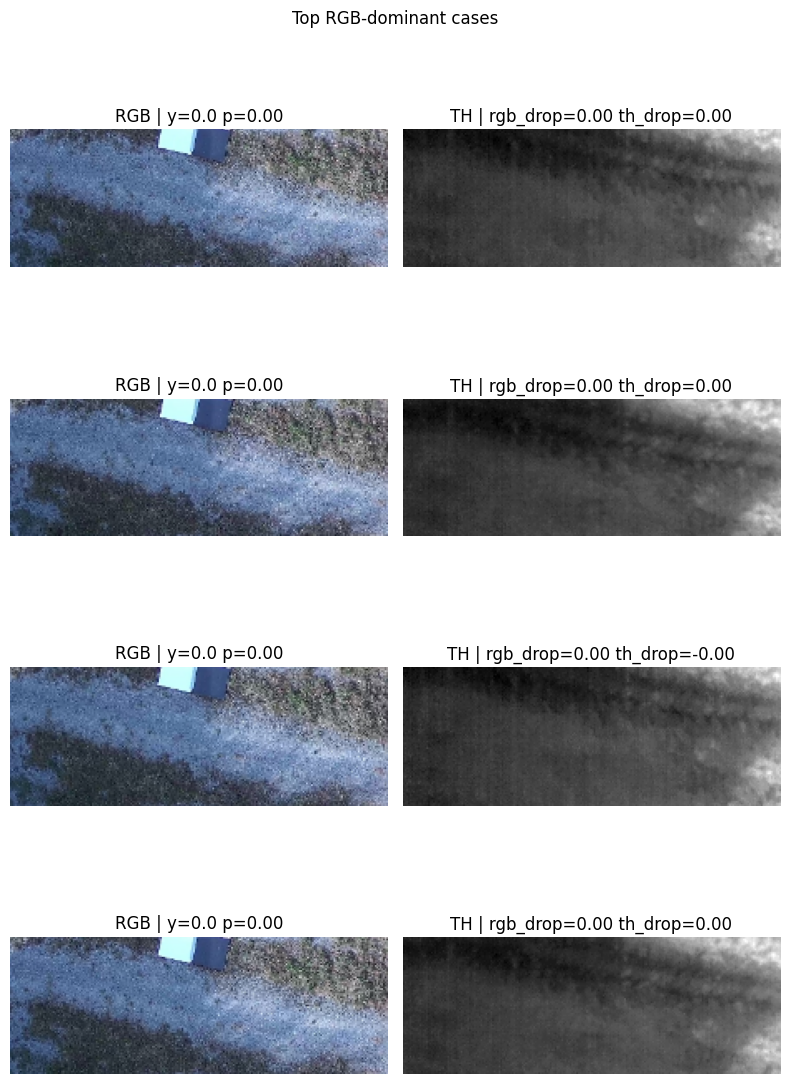

In [ ]:
def show_test_examples(test_indices, title):
    n = len(test_indices)
    fig, axes = plt.subplots(n, 2, figsize=(8, 3 * n))
    if n == 1:
        axes = np.array([axes])

    for i, ti in enumerate(test_indices):
        row = test_ds.df.iloc[ti]
        rgb = np.load(row["rgb_npy"])[:, :, ::-1]
        th = np.load(row["thermal_npy"])

        meta = ablate_df.iloc[ti]
        axes[i, 0].imshow(rgb)
        axes[i, 0].axis("off")
        axes[i, 0].set_title(f"RGB | y={meta.label} p={meta.p_full:.2f}")

        axes[i, 1].imshow(th, cmap="gray")
        axes[i, 1].axis("off")
        axes[i, 1].set_title(
            f"TH | rgb_drop={meta.rgb_drop:.2f} th_drop={meta.th_drop:.2f}"
        )

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


show_test_examples(top_th["test_index"].tolist()[:4], "Top Thermal-dominant cases")
show_test_examples(top_rgb["test_index"].tolist()[:4], "Top RGB-dominant cases")

# Nearest Neighbor Prototype Explanations

We’ll build an embedding bank for the whole dataset (train+test) using the late-fusion embedding z = [z_rgb, z_th], then retrieve nearest neighbors.

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity


@torch.no_grad()
def get_embedding_from_batch(late_model, rgb, th):
    late_model.eval()
    z1 = late_model.proj_rgb(late_model.rgb_net(rgb))
    z2 = late_model.proj_th(late_model.th_net(th))
    z = torch.cat([z1, z2], dim=1)
    z = F.normalize(z, p=2, dim=1)  # normalize for cosine similarity
    return z.detach().cpu().numpy()


def build_embedding_bank(dataset, loader, name="bank"):
    all_z = []
    all_y = []
    all_idx = []

    idx_counter = 0
    for rgb, th, y in loader:
        rgb = rgb.to(DEVICE)
        th = th.to(DEVICE)
        z = get_embedding_from_batch(late_model, rgb, th)
        all_z.append(z)
        all_y.append(y.numpy())

        # store dataset indices in the same order as loader emits
        bs = y.shape[0]
        all_idx.extend(list(range(idx_counter, idx_counter + bs)))
        idx_counter += bs

    Z = np.concatenate(all_z, axis=0)
    Y = np.concatenate(all_y, axis=0)
    IDX = np.array(all_idx)
    print(f"{name}: Z={Z.shape} Y={Y.shape}")
    return Z, Y, IDX


# Build for TRAIN and TEST separately
train_loader_nn = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=False
)
test_loader_nn = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=False
)

Z_train, Y_train, I_train = build_embedding_bank(train_ds, train_loader_nn, "train")
Z_test, Y_test, I_test = build_embedding_bank(test_ds, test_loader_nn, "test")


train: Z=(989, 512) Y=(989,)
test: Z=(366, 512) Y=(366,)


In [ ]:
def retrieve_neighbors(query_idx, k=5):
    """
    query_idx: index in test_ds
    returns: indices of nearest neighbors in TRAIN set
    """
    q = Z_test[query_idx : query_idx + 1]  # (1,D)
    sims = cosine_similarity(q, Z_train)[0]  # (N_train,)
    nn = np.argsort(-sims)[:k]
    return nn, sims[nn]

In [ ]:
def show_query_and_neighbors(query_idx, k=5):
    nn_idx, nn_sims = retrieve_neighbors(query_idx, k=k)

    # Query raw
    q_row = test_ds.df.iloc[query_idx]
    q_rgb = np.load(q_row["rgb_npy"])[:, :, ::-1]
    q_th = np.load(q_row["thermal_npy"])
    q_lab = (
        int(test_ds.df.iloc[query_idx]["label"])
        if "label" in test_ds.df.columns
        else int(Y_test[query_idx])
    )

    fig, axes = plt.subplots(k + 1, 2, figsize=(8, 3 * (k + 1)))

    axes[0, 0].imshow(q_rgb)
    axes[0, 0].axis("off")
    axes[0, 1].imshow(q_th, cmap="gray")
    axes[0, 1].axis("off")
    axes[0, 0].set_title(f"QUERY RGB | y={q_lab}")
    axes[0, 1].set_title("QUERY Thermal")

    for i, (ni, sim) in enumerate(zip(nn_idx, nn_sims), start=1):
        tr_row = train_ds.df.iloc[ni]
        tr_rgb = np.load(tr_row["rgb_npy"])[:, :, ::-1]
        tr_th = np.load(tr_row["thermal_npy"])
        tr_lab = (
            int(train_ds.df.iloc[ni]["label"])
            if "label" in train_ds.df.columns
            else int(Y_train[ni])
        )

        axes[i, 0].imshow(tr_rgb)
        axes[i, 0].axis("off")
        axes[i, 1].imshow(tr_th, cmap="gray")
        axes[i, 1].axis("off")
        axes[i, 0].set_title(f"NN {i} RGB | y={tr_lab} | sim={sim:.3f}")
        axes[i, 1].set_title("NN Thermal")

    plt.tight_layout()
    plt.show()

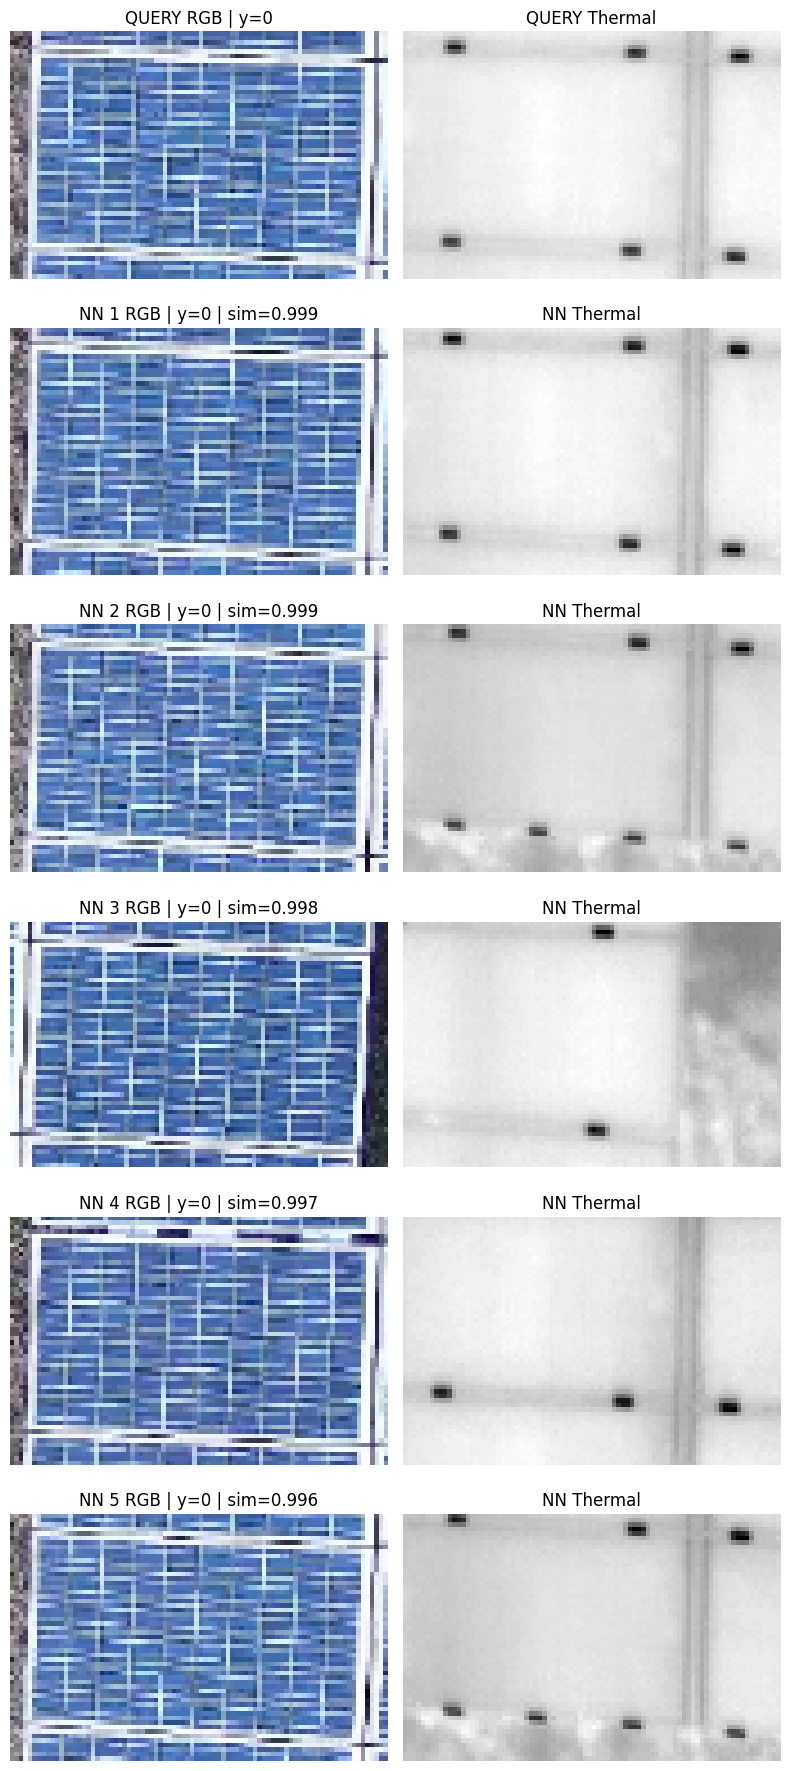

In [ ]:
show_query_and_neighbors(query_idx=0, k=5)

What you now gained (why this is valuable)
(1) Global map

You can say:

“Across the test set, thermal tends to dominate for true defects, while RGB becomes important in ambiguous/shadow cases.”

(3) Prototypes

You can say:

“For each prediction, we can retrieve similar past examples in embedding space, providing an intuitive case-based explanation.”

These are very strong additions that go beyond saliency maps.

# CCME (Counterfactual Cross-Modal Explanation)

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# If not already set:
late_model.eval()


@torch.no_grad()
def get_parts_embeddings(late_model, rgb, th):
    """
    Returns (z_rgb, z_th) where each is (B, emb_dim) torch tensor on DEVICE
    """
    late_model.eval()
    z_rgb = late_model.proj_rgb(late_model.rgb_net(rgb))
    z_th = late_model.proj_th(late_model.th_net(th))
    return z_rgb, z_th


@torch.no_grad()
def prob_from_parts(late_model, z_rgb, z_th):
    """
    z_rgb, z_th: (B, emb_dim) tensors on DEVICE
    returns prob of class 1 as numpy (B,)
    """
    z = torch.cat([z_rgb, z_th], dim=1)
    logits = late_model.head(z)
    prob1 = torch.softmax(logits, dim=1)[:, 1]
    return prob1.detach().cpu().numpy()


def pred_class_from_prob(prob, threshold=0.5):
    return (prob >= threshold).astype(int)

In [ ]:
from torch.utils.data import DataLoader

# Use shuffle=False so index order is stable
train_loader_ccme = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=False
)

MAX_BASE_SAMPLES = 800  # increase if you want; 300–800 is usually enough

zrgb_list = []
zth_list = []
count = 0

late_model.eval()

for rgb, th, y in train_loader_ccme:
    rgb = rgb.to(DEVICE)
    th = th.to(DEVICE)
    y = y.numpy()

    # keep only normal samples (label 0)
    mask0 = y == 0
    if mask0.sum() == 0:
        continue

    rgb0 = rgb[mask0]
    th0 = th[mask0]

    z_rgb, z_th = get_parts_embeddings(late_model, rgb0, th0)
    zrgb_list.append(z_rgb.detach().cpu())
    zth_list.append(z_th.detach().cpu())

    count += mask0.sum()
    if count >= MAX_BASE_SAMPLES:
        break

ZRGB0 = torch.cat(zrgb_list, dim=0)  # (N0, emb_dim) on CPU
ZTH0 = torch.cat(zth_list, dim=0)

zrgb_base = ZRGB0.mean(dim=0).to(DEVICE)  # (emb_dim,)
zth_base = ZTH0.mean(dim=0).to(DEVICE)

print("Baseline built from normal samples:", int(ZRGB0.shape[0]))
print(
    "zrgb_base shape:", tuple(zrgb_base.shape), "zth_base shape:", tuple(zth_base.shape)
)

Baseline built from normal samples: 804
zrgb_base shape: (256,) zth_base shape: (256,)


In [ ]:
@torch.no_grad()
def find_min_alpha_for_target(
    late_model,
    z_rgb_orig,
    z_th_orig,
    zrgb_base,
    zth_base,
    vary="th",  # "th" or "rgb"
    target_class=1,
    threshold=0.5,
    n_steps=22,  # binary search steps
):
    """
    Returns alpha in [0,1] if target reachable; else returns np.nan
    z_rgb_orig, z_th_orig: (B, emb_dim) on DEVICE
    zrgb_base, zth_base: (emb_dim,) on DEVICE
    """
    B = z_rgb_orig.shape[0]

    # quick checks at alpha=0 and alpha=1
    if vary == "th":
        z_rgb_fixed = z_rgb_orig
        z_th_0 = zth_base[None, :].repeat(B, 1)
        z_th_1 = z_th_orig
        p0 = prob_from_parts(late_model, z_rgb_fixed, z_th_0)
        p1 = prob_from_parts(late_model, z_rgb_fixed, z_th_1)
    else:
        z_th_fixed = z_th_orig
        z_rgb_0 = zrgb_base[None, :].repeat(B, 1)
        z_rgb_1 = z_rgb_orig
        p0 = prob_from_parts(late_model, z_rgb_0, z_th_fixed)
        p1 = prob_from_parts(late_model, z_rgb_1, z_th_fixed)

    c0 = pred_class_from_prob(p0, threshold)
    c1 = pred_class_from_prob(p1, threshold)

    # If even alpha=1 doesn't reach target class → unreachable
    unreachable = c1 != target_class
    # If alpha=0 already is target class → alpha = 0
    already = c0 == target_class

    # initialize result
    alpha_out = np.full((B,), np.nan, dtype=np.float32)
    alpha_out[already] = 0.0

    # candidates for search: not already, not unreachable
    active = (~already) & (~unreachable)
    if active.sum() == 0:
        return alpha_out

    lo = np.zeros(B, dtype=np.float32)
    hi = np.ones(B, dtype=np.float32)

    for _ in range(n_steps):
        mid = (lo + hi) / 2.0
        mid_t = torch.tensor(mid, device=DEVICE).float()[:, None]  # (B,1)

        if vary == "th":
            z_th_mid = (1 - mid_t) * zth_base[None, :] + mid_t * z_th_orig
            p_mid = prob_from_parts(late_model, z_rgb_orig, z_th_mid)
        else:
            z_rgb_mid = (1 - mid_t) * zrgb_base[None, :] + mid_t * z_rgb_orig
            p_mid = prob_from_parts(late_model, z_rgb_mid, z_th_orig)

        c_mid = pred_class_from_prob(p_mid, threshold)

        # If mid reaches target, move hi down; else move lo up
        reach = c_mid == target_class
        # only update active ones
        hi = np.where(active & reach, mid, hi)
        lo = np.where(active & (~reach), mid, lo)

    alpha_out[active] = hi[active]
    return alpha_out

In [ ]:
test_loader_ccme = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=False
)

rows = []
idx_counter = 0

TARGET_CLASS = 1  # defect
THRESHOLD = 0.5  # decision threshold
MAX_TEST_SAMPLES = None  # set like 400 for quicker runs; None = full test

late_model.eval()

for rgb, th, y in test_loader_ccme:
    rgb = rgb.to(DEVICE)
    th = th.to(DEVICE)
    y_np = y.numpy()
    B = y.shape[0]

    z_rgb, z_th = get_parts_embeddings(late_model, rgb, th)

    # baseline/full probs
    p_full = prob_from_parts(late_model, z_rgb, z_th)

    # CCME alphas
    alpha_th = find_min_alpha_for_target(
        late_model,
        z_rgb,
        z_th,
        zrgb_base,
        zth_base,
        vary="th",
        target_class=TARGET_CLASS,
        threshold=THRESHOLD,
    )
    alpha_rgb = find_min_alpha_for_target(
        late_model,
        z_rgb,
        z_th,
        zrgb_base,
        zth_base,
        vary="rgb",
        target_class=TARGET_CLASS,
        threshold=THRESHOLD,
    )

    for i in range(B):
        rows.append(
            {
                "test_index": idx_counter,
                "label": int(y_np[i]),
                "p_full": float(p_full[i]),
                "alpha_th": float(alpha_th[i]) if np.isfinite(alpha_th[i]) else np.nan,
                "alpha_rgb": float(alpha_rgb[i])
                if np.isfinite(alpha_rgb[i])
                else np.nan,
            }
        )
        idx_counter += 1

    if MAX_TEST_SAMPLES is not None and idx_counter >= MAX_TEST_SAMPLES:
        break

ccme_df = pd.DataFrame(rows)
ccme_df.head(), len(ccme_df)

(   test_index  label    p_full  alpha_th  alpha_rgb
 0           0      0  0.006965       NaN        NaN
 1           1      0  0.127115       NaN        NaN
 2           2      0  0.459672       NaN        0.0
 3           3      0  0.006831       NaN        NaN
 4           4      0  0.963831  0.628156        0.0,
 366)

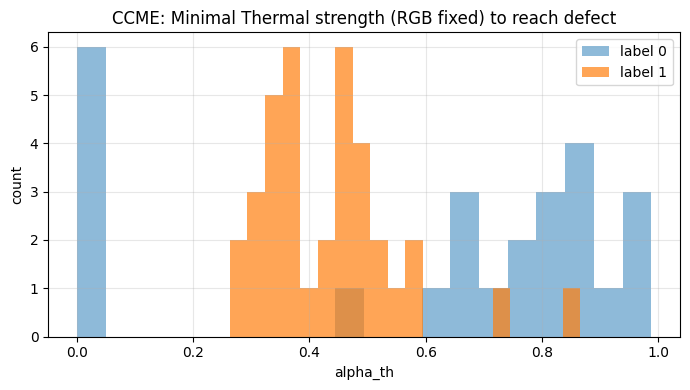

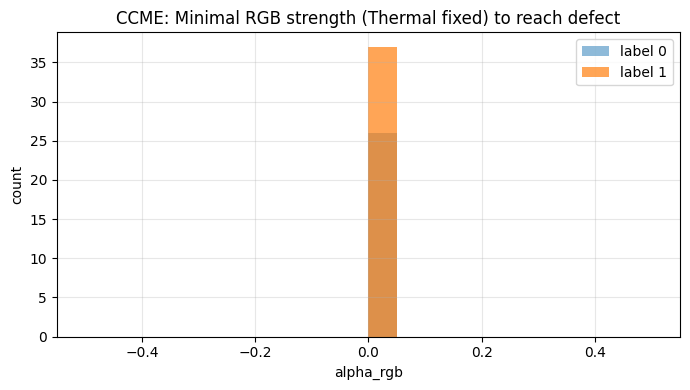

In [ ]:
def plot_alpha_hist(df, col, title):
    plt.figure(figsize=(7, 4))
    pos = df[df["label"] == 1][col].dropna()
    neg = df[df["label"] == 0][col].dropna()

    plt.hist(neg, bins=20, alpha=0.5, label="label 0")
    plt.hist(pos, bins=20, alpha=0.7, label="label 1")
    plt.xlabel(col)
    plt.ylabel("count")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


plot_alpha_hist(
    ccme_df, "alpha_th", "CCME: Minimal Thermal strength (RGB fixed) to reach defect"
)
plot_alpha_hist(
    ccme_df, "alpha_rgb", "CCME: Minimal RGB strength (Thermal fixed) to reach defect"
)

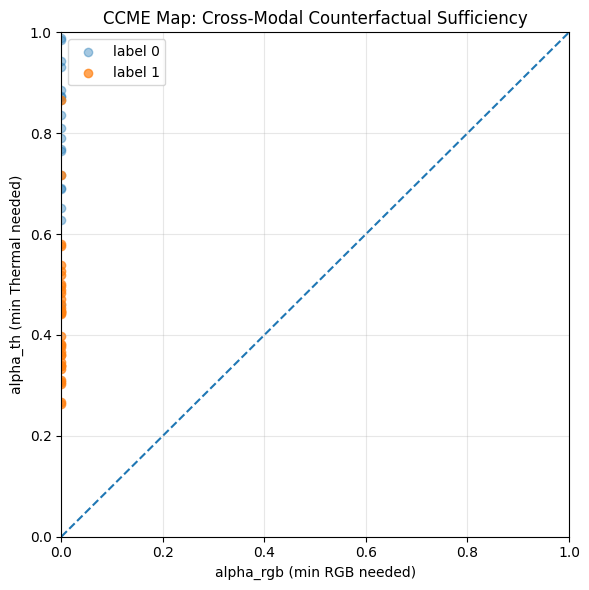

Rows with finite alphas: 55 / 366
Median alpha_th (label1): 0.4414987564086914
Median alpha_rgb (label1): 0.0


In [ ]:
plt.figure(figsize=(6, 6))
dfp = ccme_df.dropna(subset=["alpha_th", "alpha_rgb"])

pos = dfp[dfp["label"] == 1]
neg = dfp[dfp["label"] == 0]

plt.scatter(neg["alpha_rgb"], neg["alpha_th"], alpha=0.4, label="label 0")
plt.scatter(pos["alpha_rgb"], pos["alpha_th"], alpha=0.7, label="label 1")

plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.xlabel("alpha_rgb (min RGB needed)")
plt.ylabel("alpha_th (min Thermal needed)")
plt.title("CCME Map: Cross-Modal Counterfactual Sufficiency")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Rows with finite alphas:", len(dfp), "/", len(ccme_df))
print("Median alpha_th (label1):", np.nanmedian(pos["alpha_th"]))
print("Median alpha_rgb (label1):", np.nanmedian(pos["alpha_rgb"]))

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


def overlay_cam_on_rgb(rgb_uint8, cam_01, alpha=0.45):
    """
    rgb_uint8: H,W,3 RGB uint8
    cam_01: H,W float in [0,1]
    returns overlay RGB uint8
    """
    cam_uint8 = (cam_01 * 255).astype(np.uint8)
    heat = cv2.applyColorMap(cam_uint8, cv2.COLORMAP_JET)[:, :, ::-1]  # to RGB
    overlay = (alpha * heat + (1 - alpha) * rgb_uint8).astype(np.uint8)
    return overlay


def overlay_cam_on_gray(gray_uint8, cam_01, alpha=0.45):
    """
    gray_uint8: H,W uint8
    cam_01: H,W float in [0,1]
    returns overlay RGB uint8
    """
    base = np.stack([gray_uint8] * 3, axis=2)
    return overlay_cam_on_rgb(base, cam_01, alpha=alpha)

In [ ]:
import torch.nn.functional as F


class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.layer = target_layer
        self.activations = None
        self.gradients = None

        self.layer.register_forward_hook(self._forward)
        self.layer.register_full_backward_hook(self._backward)

    def _forward(self, module, inp, out):
        self.activations = out

    def _backward(self, module, grad_in, grad_out):
        self.gradients = grad_out[0]

    def __call__(self, forward_fn, class_idx=None):
        self.model.zero_grad()
        logits = forward_fn()
        if class_idx is None:
            class_idx = logits.argmax(dim=1).item()
        score = logits[:, class_idx].sum()
        score.backward()

        w = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = (w * self.activations).sum(dim=1)
        cam = F.relu(cam)[0].detach().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() + 1e-8)
        return cam

In [ ]:
def get_test_item(idx):
    # tensors (model input)
    rgb_t, th_t, y = test_ds[idx]
    rgb_t = rgb_t.unsqueeze(0).to(DEVICE)
    th_t = th_t.unsqueeze(0).to(DEVICE)

    # raw (for plotting)
    row = test_ds.df.iloc[idx]
    rgb_raw = np.load(row["rgb_npy"])[:, :, ::-1].copy()  # RGB uint8
    th_raw = np.load(row["thermal_npy"]).copy()  # gray uint8

    return rgb_raw, th_raw, rgb_t, th_t, int(y)

In [ ]:
def get_latefusion_branch_cams(rgb_t, th_t):
    late_model.eval()

    cam_rgb = GradCAM(late_model, late_model.rgb_net.layer4[-1].conv2)
    cam_th = GradCAM(late_model, late_model.th_net.layer4[-1].conv2)

    heat_rgb = cam_rgb(lambda: late_model(rgb_t, th_t))
    heat_th = cam_th(lambda: late_model(rgb_t, th_t))

    # resize to input size if needed
    H, W = rgb_t.shape[-2], rgb_t.shape[-1]
    heat_rgb = cv2.resize(heat_rgb, (W, H))
    heat_th = cv2.resize(heat_th, (W, H))
    return heat_rgb, heat_th

In [ ]:
K = 4  # number of examples per category

df_pos = ccme_df[ccme_df["label"] == 1].copy()

# Thermal-sufficient defects: very low alpha_th
thermal_sufficient = df_pos.dropna(subset=["alpha_th"]).sort_values("alpha_th").head(K)

# RGB-sufficient defects: very low alpha_rgb
rgb_sufficient = df_pos.dropna(subset=["alpha_rgb"]).sort_values("alpha_rgb").head(K)

# Hard defects: both high (needs both modalities)
hard = (
    df_pos.dropna(subset=["alpha_th", "alpha_rgb"])
    .sort_values(by=["alpha_th", "alpha_rgb"], ascending=False)
    .head(K)
)

(
    thermal_sufficient[["test_index", "p_full", "alpha_th", "alpha_rgb"]],
    rgb_sufficient[["test_index", "p_full", "alpha_th", "alpha_rgb"]],
    hard[["test_index", "p_full", "alpha_th", "alpha_rgb"]],
)

(     test_index    p_full  alpha_th  alpha_rgb
 63           63  0.999948  0.263287        0.0
 259         259  0.999942  0.266825        0.0
 272         272  0.999779  0.302665        0.0
 44           44  0.999909  0.305867        0.0,
      test_index    p_full  alpha_th  alpha_rgb
 22           22  0.974845  0.575507        0.0
 259         259  0.999942  0.266825        0.0
 261         261  0.291689       NaN        0.0
 263         263  0.994307  0.488342        0.0,
      test_index    p_full  alpha_th  alpha_rgb
 358         358  0.723668  0.865461        0.0
 319         319  0.924143  0.716595        0.0
 132         132  0.983147  0.579830        0.0
 22           22  0.974845  0.575507        0.0)

In [ ]:
import cv2
import numpy as np


def overlay_cam_on_rgb(rgb_uint8, cam_01, alpha=0.45):
    """
    rgb_uint8: H,W,3 RGB uint8
    cam_01: h,w float in [0,1] (any size)
    returns overlay RGB uint8 (H,W,3)
    """
    H, W = rgb_uint8.shape[:2]

    # Resize CAM to match image size
    cam_resized = cv2.resize(cam_01, (W, H), interpolation=cv2.INTER_LINEAR)
    cam_uint8 = (cam_resized * 255).astype(np.uint8)

    heat = cv2.applyColorMap(cam_uint8, cv2.COLORMAP_JET)[:, :, ::-1]  # BGR->RGB
    overlay = (alpha * heat + (1 - alpha) * rgb_uint8).astype(np.uint8)
    return overlay


def overlay_cam_on_gray(gray_uint8, cam_01, alpha=0.45):
    """
    gray_uint8: H,W uint8
    cam_01: h,w float in [0,1] (any size)
    returns overlay RGB uint8 (H,W,3)
    """
    base = np.stack([gray_uint8] * 3, axis=2)
    return overlay_cam_on_rgb(base, cam_01, alpha=alpha)

In [ ]:
def get_latefusion_branch_cams(rgb_t, th_t):
    late_model.eval()

    cam_rgb = GradCAM(late_model, late_model.rgb_net.layer4[-1].conv2)
    cam_th = GradCAM(late_model, late_model.th_net.layer4[-1].conv2)

    heat_rgb = cam_rgb(lambda: late_model(rgb_t, th_t))
    heat_th = cam_th(lambda: late_model(rgb_t, th_t))

    # Return raw CAM maps; overlay fn will resize to raw image size
    return heat_rgb, heat_th

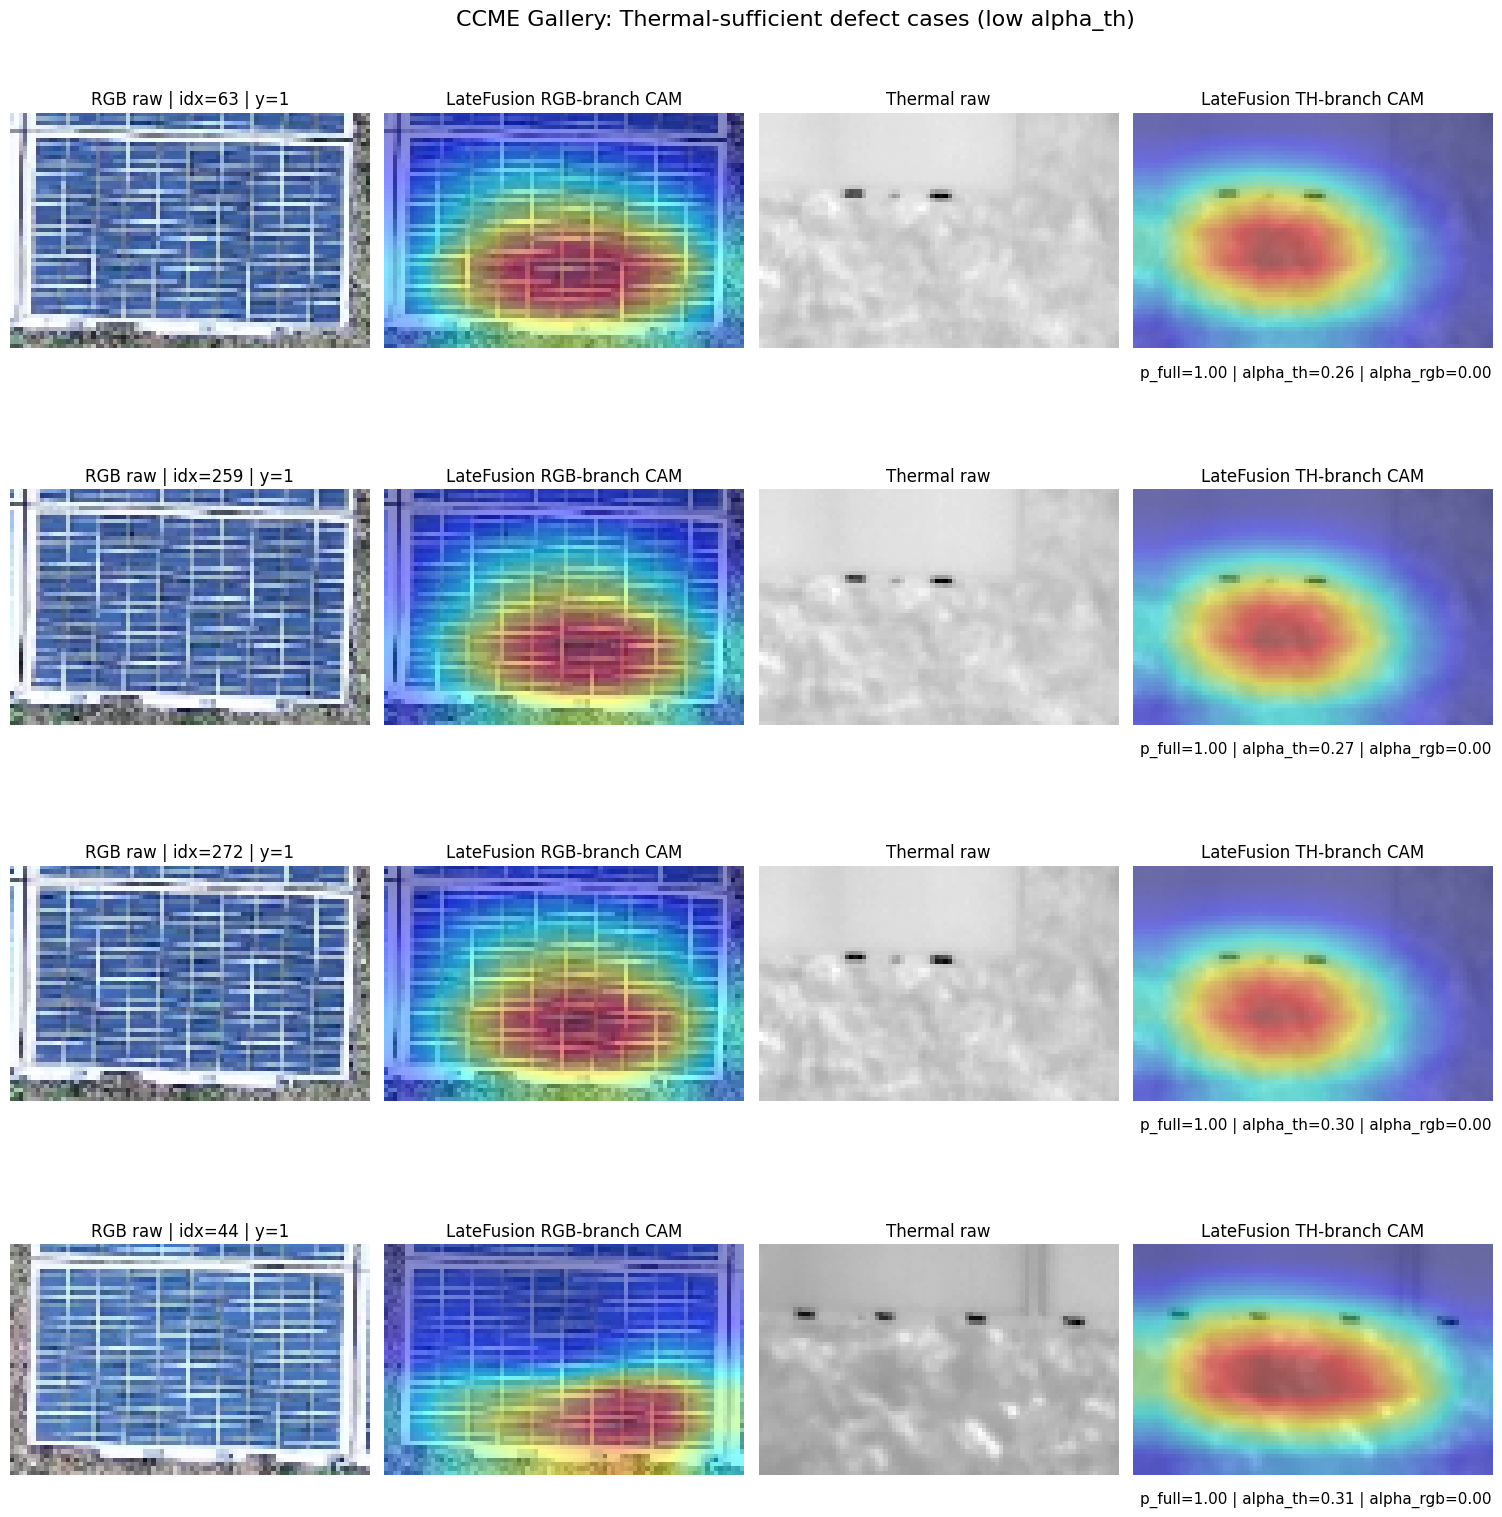

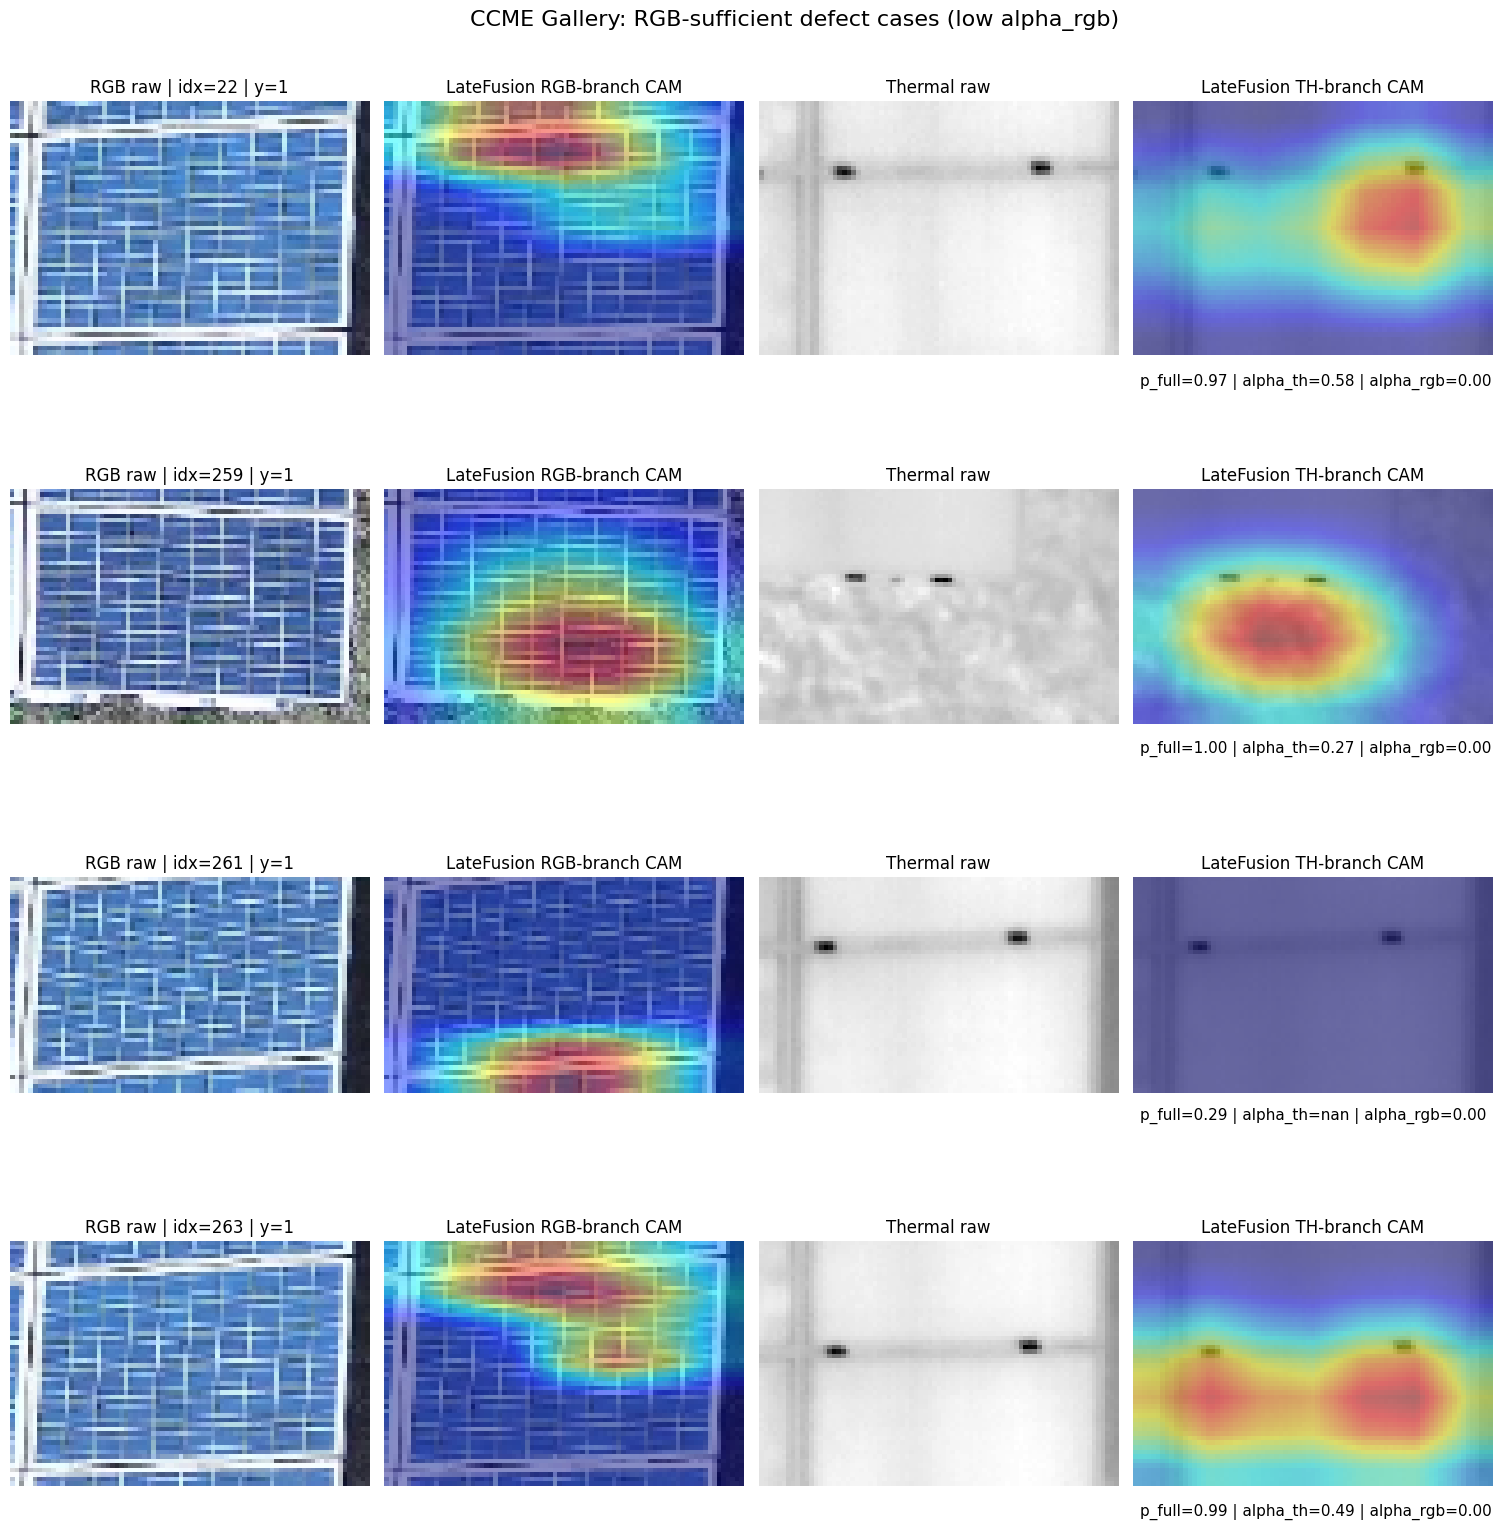

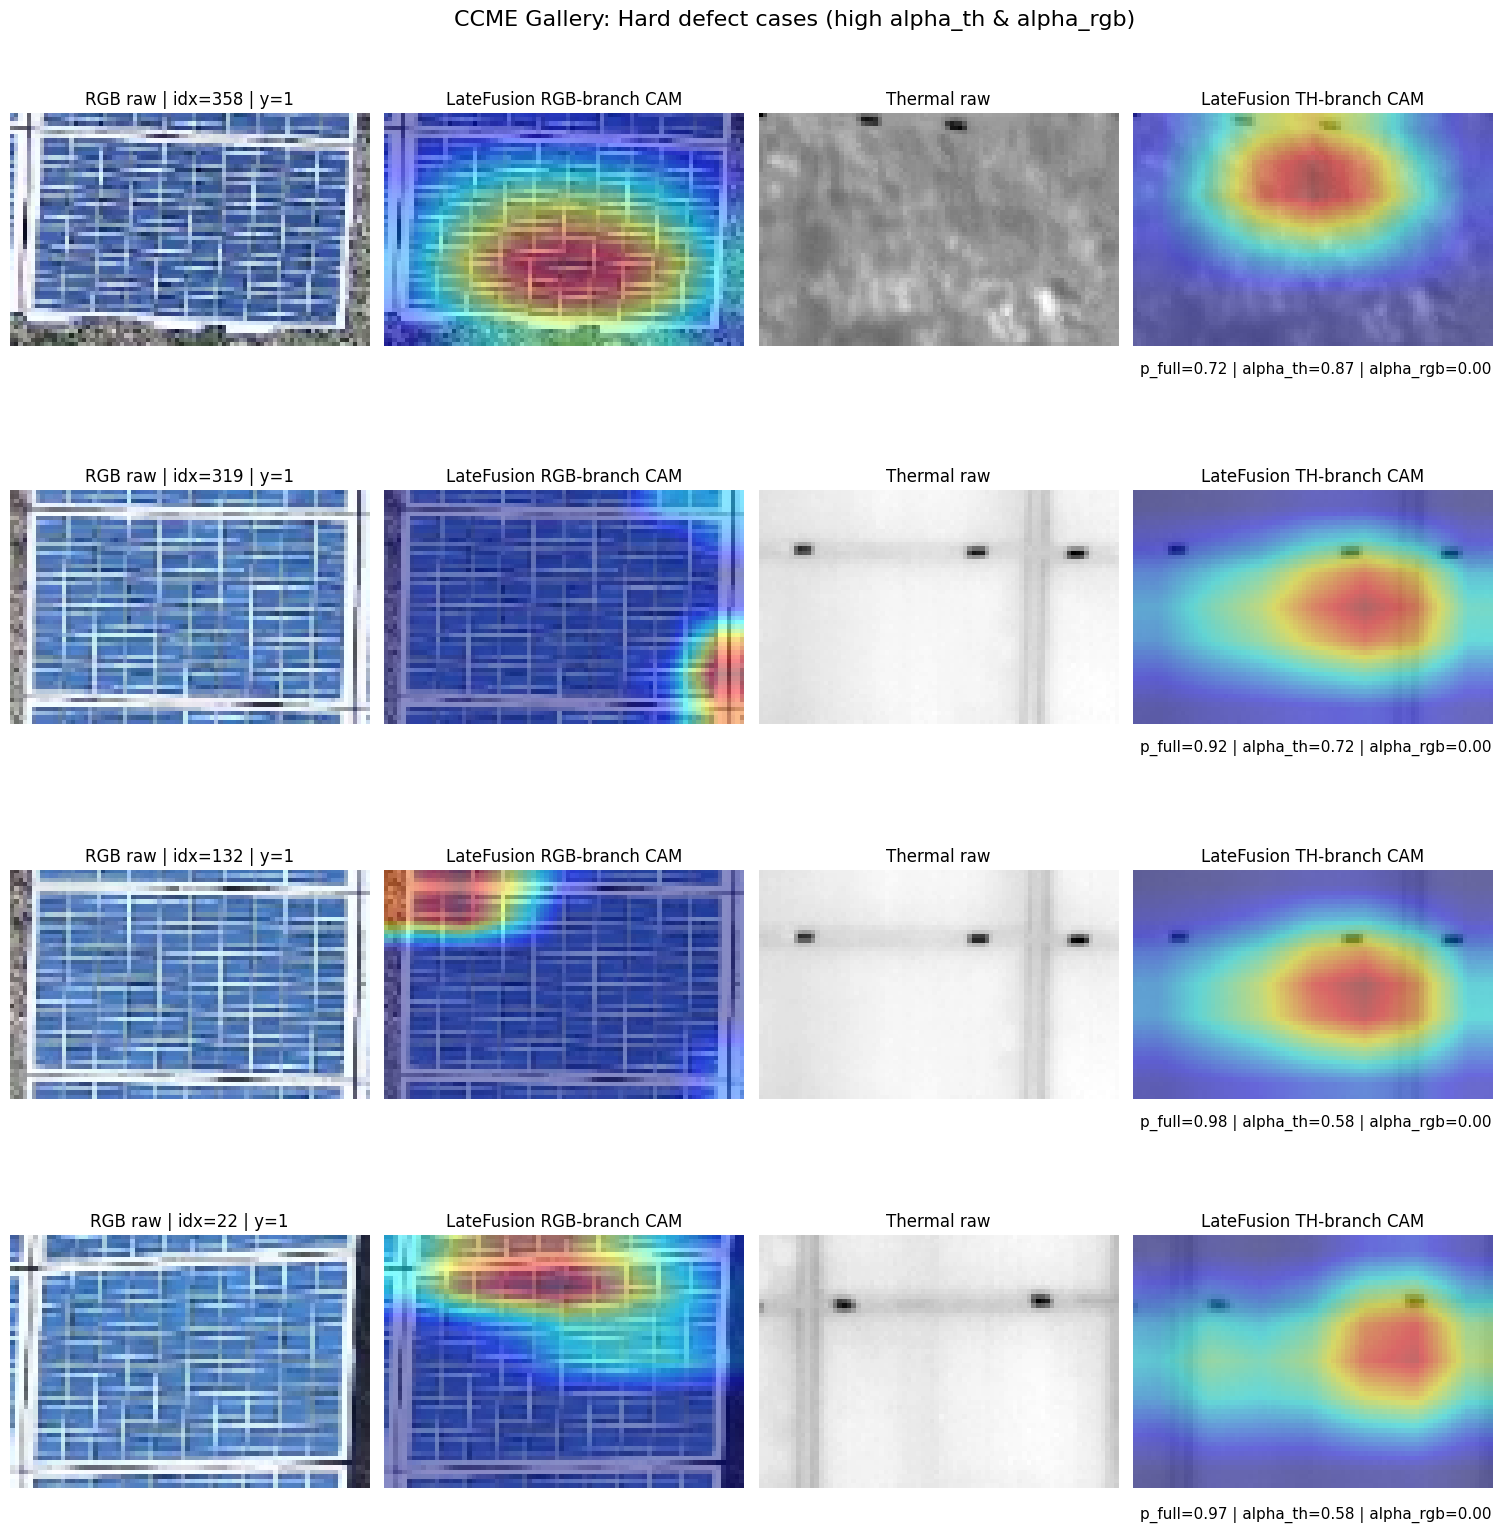

In [ ]:
show_ccme_gallery(
    thermal_sufficient, "CCME Gallery: Thermal-sufficient defect cases (low alpha_th)"
)
show_ccme_gallery(
    rgb_sufficient, "CCME Gallery: RGB-sufficient defect cases (low alpha_rgb)"
)
show_ccme_gallery(hard, "CCME Gallery: Hard defect cases (high alpha_th & alpha_rgb)")
